# Multicoil SH versus SH+ACDC analysis

Cleaned copy of `mc_vs_siemens_apollo.ipynb`. Run the cells from top to bottom.
All outputs were cleared; this notebook has not been executed during cleanup.

The study uses multicoil acquisitions only. The 3D analysis includes all eight
participants. The 2D comparison excludes sub-07. ACDC is volume-wise for 3D and
slice-wise for 2D. Cross-dimensional tests use participants available in all four conditions.

Keep `multicoil_paths.py` and `multicoil_paths_2d.py` beside this notebook.
Edit the settings below to change participant inclusion, DI method, vertebral levels,
prediction display, or marker spacing. Rerun the relevant calculation cells after edits.

Whole-volume statistics use all finite voxels in each acquisition's own masks;
no slices are removed based on prediction coverage. Masks use a binary `> 0` policy,
and spatial SD uses `ddof=0`. GM/WM overlap remains permitted for CNR, matching the
source notebook's current behavior. These spatial-SD-based CNRs are not independent
thermal-noise measurements. Susceptibility maps are assumed already in ppm;
no unit conversion or re-referencing is applied. Anatomical coverage can differ.

Participant mapping: sub-01/chi_026, sub-02/chi_030, sub-03/chi_032,
sub-04/chi_033, sub-05/chi_035, sub-06/chi_036, sub-07/chi_037, sub-08/chi_038.


In [1]:
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import ttest_rel
from IPython.display import display


In [2]:
import importlib
import multicoil_paths as data_paths_3d
import multicoil_paths_2d as data_paths_2d

importlib.reload(data_paths_3d)
importlib.reload(data_paths_2d)

participants_3d = data_paths_3d.participants
participants_2d = data_paths_2d.participants

participants_by_dimension = {
    "2D": participants_2d,
    "3D": participants_3d,
}

# Preserve compatibility with your existing 3D cells:
participants = participants_3d
print("3D file:", data_paths_3d.__file__)
print("2D file:", data_paths_2d.__file__)

print("3D participants:", list(participants_3d))
print("2D participants:", list(participants_2d))


3D file: c:\Users\Admin\Documents\msc_project\Image-processing-strategies\realtime_shimming\multicoil_paths.py
2D file: c:\Users\Admin\Documents\msc_project\Image-processing-strategies\realtime_shimming\multicoil_paths_2d.py
3D participants: ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08']
2D participants: ['sub-05', 'sub-06', 'sub-07', 'sub-08']


## Settings
One participant selection is used for whole-volume B0 SD, CNR, and their plots/tests. Three-dimensional diagnostic analyses use all entries in `participants_3d`.


In [3]:
MEASURED_CONDITIONS = ("sh", "sh_acdc")
CONDITION_LABELS = {"sh": "SH", "sh_acdc": "SH+ACDC"}
CONDITION_STYLES = {
    "sh": ("SH", "#93c5fd", "#1e40af"),
    "sh_acdc": ("SH+ACDC", "#fdba74", "#c2410c"),
}

INCLUDED_PARTICIPANTS = {
    "2D": ("sub-05", "sub-06", "sub-08"),
    "3D": tuple(participants_3d),
}
# To restrict 3D to participants who also had 2D acquisitions:
# INCLUDED_PARTICIPANTS["3D"] = ("sub-05", "sub-06", "sub-07", "sub-08")
# Remove a participant with:
INCLUDED_PARTICIPANTS["3D"] = tuple(p for p in participants_3d if p != "sub-07")

DI_METHOD = "closedform"  # "closedform", "medi", or "fansi"
DI_KEYS = {"closedform": "chimap_closedform_path",
           "medi": "chimap_medi_path", "fansi": "chimap_fansi_path"}
DI_LABELS = {"closedform": "CLOSED-FORM", "medi": "MEDI", "fansi": "FANSI"}
if DI_METHOD not in DI_KEYS:
    raise ValueError("Choose closedform, medi, or fansi")

VERT_LEVELS = (2, 3, 4, 5)
FIELDMAP_METRIC = "Mean"  # "Mean", "SD", or "RMSE"
DI_TEST_METRIC = "SD"  # "SD" or "Mean"
TARGET_B0 = 0.0  # Hz
SHOW_PREDICTED = True
SHOW_CONDITION_LEGEND = True
SHOW_PARTICIPANT_LEGEND = True
SHOW_DI_C2_C3_TABLE = False  # Optional diagnostic table retained from the original.
MARKER_SPREAD = 0.22
BOX_FIGSIZE = (9, 5)

PARTICIPANT_STYLES = {
    "sub-01": {"color": "#0072B2", "marker": "o"},
    "sub-02": {"color": "#D55E00", "marker": "s"},
    "sub-03": {"color": "#009E73", "marker": "^"},
    "sub-04": {"color": "#CC79A7", "marker": "D"},
    "sub-05": {"color": "#56B4E9", "marker": "P"},
    "sub-06": {"color": "#E69F00", "marker": "X"},
    "sub-07": {"color": "#882255", "marker": "v"},
    "sub-08": {"color": "#332288", "marker": "*"},
}
GROUPS = [("2D", "sh"), ("2D", "sh_acdc"),
          ("3D", "sh"), ("3D", "sh_acdc")]


## Shared calculation helpers
These functions centralize image-grid checks, mask extraction, whole-volume CNR, vertebral metrics, and paired tests.


In [4]:
def load_aligned_images(paths, keys):
    for key in keys:
        if not paths.get(key) or not Path(paths[key]).is_file():
            raise FileNotFoundError(f"{key}: {paths.get(key)!r}")
    images = [nib.load(paths[key]) for key in keys]
    reference = images[0]
    if len(reference.shape) != 3 or any(
        image.shape != reference.shape or not np.allclose(
            image.affine, reference.affine, atol=1e-4, rtol=0)
        for image in images[1:]
    ):
        raise ValueError("Images and masks must share the same 3D grid")
    return [image.get_fdata() for image in images]


def masked_values(image, mask):
    return image[np.isfinite(image) & np.isfinite(mask) & (mask > 0)]


def calculate_tissue_statistics(paths, image_key):
    image, gm_mask, wm_mask = load_aligned_images(
        paths, (image_key, "gm_mask_path", "wm_mask_path"))
    result = {}
    for tissue, mask in (("GM", gm_mask), ("WM", wm_mask)):
        values = masked_values(image, mask)
        if values.size < 2:
            raise ValueError(f"Insufficient finite {tissue} voxels")
        result.update({f"{tissue} Mean": values.mean(),
                       f"{tissue} SD": values.std(ddof=0),
                       f"{tissue} Nvox": values.size})
    return result


def calculate_whole_cnr(paths, image_key):
    # Pool tissue voxels across the volume; do not average slice-wise CNRs.
    result = calculate_tissue_statistics(paths, image_key)
    denominator = np.sqrt((result["GM SD"]**2 + result["WM SD"]**2) / 2)
    result["CNR"] = (abs(result["GM Mean"] - result["WM Mean"]) / denominator
                     if denominator > 0 else np.nan)
    return result


def calculate_vertebral_metrics(participant_paths, image_key, mask_key,
                               levels, intersect_sc=False):
    rows, missing = [], []
    for participant_id, conditions in participant_paths.items():
        for condition in MEASURED_CONDITIONS:
            paths = conditions[condition]
            keys = [image_key, mask_key, "vert_levels_path"]
            if intersect_sc:
                keys.append("sc_mask_path")
            try:
                arrays = load_aligned_images(paths, keys)
            except (ValueError, FileNotFoundError) as error:
                raise type(error)(f"{participant_id}, {condition}: {error}") from error
            image, mask, labels = arrays[:3]
            finite_labels = labels[np.isfinite(labels)]
            if not np.allclose(finite_labels, np.rint(finite_labels), atol=1e-5, rtol=0):
                raise ValueError(f"{participant_id}, {condition}: use discrete vertebral labels")
            valid = np.isfinite(image) & np.isfinite(mask) & (mask > 0)
            if intersect_sc:
                sc_mask = arrays[3]
                valid &= np.isfinite(sc_mask) & (sc_mask > 0)
            for level in levels:
                values = image[valid & (labels == level)]
                if not values.size:
                    missing.append((participant_id, condition, level))
                    continue
                rows.append({"Participant": participant_id, "Condition": condition,
                             "VertLevel": level, "Mean": values.mean(),
                             "SD": values.std(ddof=0), "Nvox": values.size,
                             "RMSE": np.sqrt(np.mean(values**2))})
    if not rows:
        raise ValueError("No usable voxels in the selected vertebral levels")
    if missing:
        print("No valid voxels for (participant, condition, level):", missing)
    return pd.DataFrame(rows)


def paired_conditions(frame, value_col):
    return (frame.pivot(index="Participant", columns="Condition", values=value_col)
            .reindex(columns=list(MEASURED_CONDITIONS))
            .replace([np.inf, -np.inf], np.nan).dropna())


def paired_test_summary(before, after):
    before, after = np.asarray(before, dtype=float), np.asarray(after, dtype=float)
    finite = np.isfinite(before) & np.isfinite(after)
    before, after = before[finite], after[finite]
    delta = after - before
    t_stat = p_value = low = high = np.nan
    if len(delta) >= 2:
        if np.all(delta == 0):
            t_stat, p_value, low, high = 0.0, 1.0, 0.0, 0.0
        else:
            test = ttest_rel(after, before, alternative="two-sided")
            interval = test.confidence_interval(confidence_level=0.95)
            t_stat, p_value = test.statistic, test.pvalue
            low, high = interval.low, interval.high
    return {"N paired": len(delta),
            "Before average": before.mean() if len(delta) else np.nan,
            "After average": after.mean() if len(delta) else np.nan,
            "Difference (after-before)": delta.mean() if len(delta) else np.nan,
            "Difference CI95 low": low, "Difference CI95 high": high,
            "t statistic": t_stat, "p raw (two-sided)": p_value}


## Shared plotting helpers
Vertebral violins show participant metrics and group medians, without connecting lines. Whole-volume boxplots use consistent participant colours and markers.


In [5]:
def plot_vertebral_violins(frame, metric, title, ylabel, levels=VERT_LEVELS,
                          show_legend=SHOW_CONDITION_LEGEND):
    fig, axes = plt.subplots(1, len(levels), figsize=(3.4 * len(levels), 4.7),
                             sharey=True, squeeze=False)
    rng = np.random.default_rng(42)
    for ax, level in zip(axes.ravel(), levels):
        paired = paired_conditions(frame.loc[frame.VertLevel == level], metric)
        for position, (condition, (label, fill, dark)) in enumerate(CONDITION_STYLES.items()):
            values = paired[condition].to_numpy()
            if len(values) >= 2 and np.ptp(values) > 1e-12:
                parts = ax.violinplot(values, positions=[position], widths=0.65,
                                      showmeans=False, showmedians=True, showextrema=False)
                for body in parts["bodies"]:
                    body.set_facecolor(fill)
                    body.set_edgecolor(dark)
                    body.set_alpha(0.45)
                parts["cmedians"].set_color(dark)
            ax.scatter(position + rng.uniform(-0.07, 0.07, len(values)), values,
                       color=dark, edgecolors="white", linewidths=0.5, s=32, zorder=3)
        level_label = f"C{level}" if level <= 7 else f"T{level - 7}"
        ax.set_title(f"{level_label} | n={len(paired)} paired")
        ax.set_xticks([0, 1], list(CONDITION_LABELS.values()))
        ax.set_xlim(-0.6, 1.6)
        ax.axhline(0, color="0.5", linestyle="--", linewidth=0.8)
        ax.grid(axis="y", alpha=0.2)
        if paired.empty:
            ax.text(0.5, 0.5, "No complete pairs", ha="center", transform=ax.transAxes)
    axes[0, 0].set_ylabel(ylabel)
    fig.suptitle(title)
    if show_legend:
        handles = [Patch(facecolor=fill, edgecolor=dark, label=label, alpha=0.8)
                   for label, fill, dark in CONDITION_STYLES.values()]
        fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
                   fontsize=15, handlelength=2.5, handleheight=1.3)
    fig.tight_layout(rect=[0, 0.14 if show_legend else 0, 1, 0.94])
    plt.show()
    return fig, axes


In [6]:
def plot_participant_boxes(
    frame,
    value_col,
    title,
    ylabel,
    figsize=(9, 5),
    ylim=None,
):
    fig, ax = plt.subplots(figsize=figsize)

    # Match participants between SH and SH+ACDC within each dimension.
    paired_by_dimension = {}

    for dimension in ("2D", "3D"):
        selected = frame.loc[
            (frame["Dimension"] == dimension)
            & frame["Participant"].isin(
                INCLUDED_PARTICIPANTS[dimension]
            )
        ]

        paired_by_dimension[dimension] = (
            selected
            .pivot(
                index="Participant",
                columns="Condition",
                values=value_col,
            )
            .reindex(columns=["sh", "sh_acdc"])
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

    # Fixed offsets make each participant's position consistent across boxes.

    # Spread only the participants actually included in this figure.
    participant_ids = sorted({
        participant_id
        for paired in paired_by_dimension.values()
        for participant_id in paired.index
    })

    offsets = dict(zip(
        participant_ids,
        np.linspace(
            -MARKER_SPREAD,
            MARKER_SPREAD,
            len(participant_ids),
        ),
    ))

    shown_participants = set()
    tick_labels = []

    for position, (dimension, condition) in enumerate(GROUPS):
        paired = paired_by_dimension[dimension]
        values = paired[condition].to_numpy()

        condition_label = "SH" if condition == "sh" else "SH+ACDC"
        tick_labels.append(
            f"{dimension} {condition_label}\nn={len(paired)}"
        )

        if not len(values):
            continue

        fill = "#93c5fd" if condition == "sh" else "#fdba74"

        box = ax.boxplot(
            [values],
            positions=[position],
            widths=0.55,
            patch_artist=True,
            showfliers=False,
            medianprops={"color": "0.25", "linewidth": 2},
        )

        box["boxes"][0].set(
            facecolor=fill,
            edgecolor="0.4",
            alpha=0.4,
        )

        for participant_id, value in paired[condition].items():
            style = PARTICIPANT_STYLES[participant_id]

            ax.scatter(
                position + offsets[participant_id],
                value,
                color=style["color"],
                marker=style["marker"],
                s=85,
                edgecolors="white",
                linewidths=0.7,
                zorder=3,
            )

            shown_participants.add(participant_id)

    ax.set_xticks(range(len(GROUPS)), tick_labels)
    ax.set(
        title=title,
        ylabel=ylabel,
        xlim=(-0.6, len(GROUPS) - 0.4),
    )

    if ylim is not None:
        ax.set_ylim(ylim)
    else:
        ax.set_ylim(bottom=0)

    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if SHOW_PARTICIPANT_LEGEND and shown_participants:
        handles = [
            Line2D(
                [], [],
                linestyle="none",
                marker=PARTICIPANT_STYLES[participant_id]["marker"],
                markerfacecolor=PARTICIPANT_STYLES[participant_id]["color"],
                markeredgecolor="white",
                markersize=9,
                label=participant_id,
            )
            for participant_id in sorted(shown_participants)
        ]

        ax.legend(
            handles=handles,
            title="Participant",
            frameon=False,
            loc="upper left",
            bbox_to_anchor=(1.02, 1),
        )

    fig.tight_layout()
    plt.show()

    return fig, ax


## 1. Three-dimensional slice-wise fieldmaps
Mean plus/minus spatial SD from the existing SCT slice-wise CSVs. Toggle predictions in Settings. Slice indices are acquisition-specific; no registration is performed here.


sub-01, sh: no metrics on slices [14, 15]; shown as gaps
sub-01, sh_acdc: no metrics on slices [0, 14, 15]; shown as gaps
sub-01, predicted_sh_acdc: no metrics on slices [14, 15]; shown as gaps
sub-02, predicted_sh_acdc: no metrics on slices [14, 15]; shown as gaps
sub-08, predicted_sh_acdc: no metrics on slices [0, 1, 14, 15]; shown as gaps


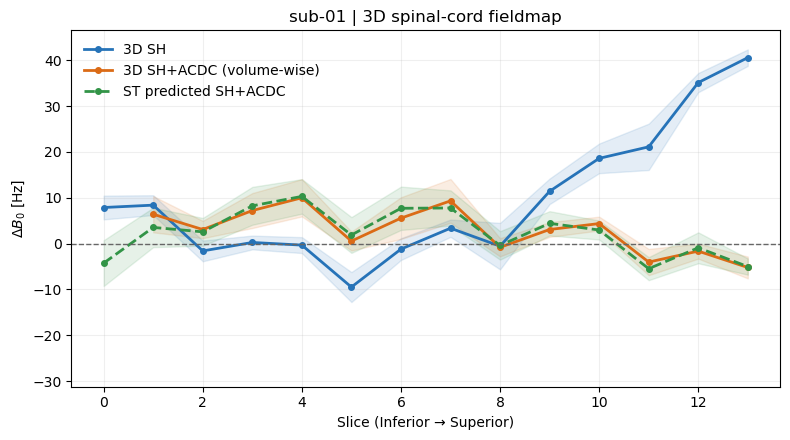

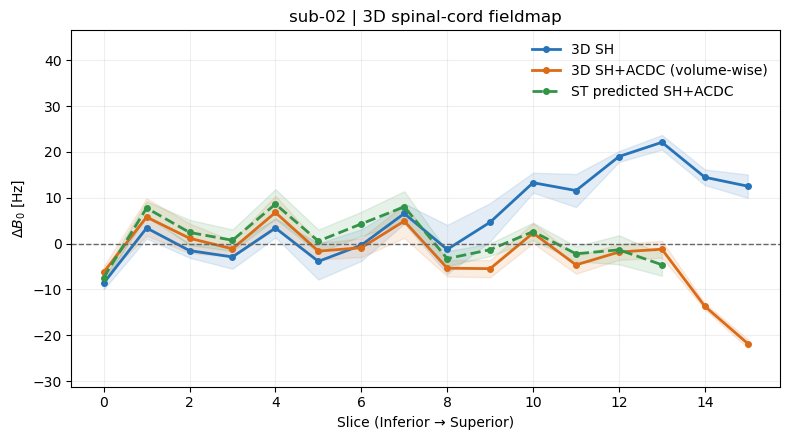

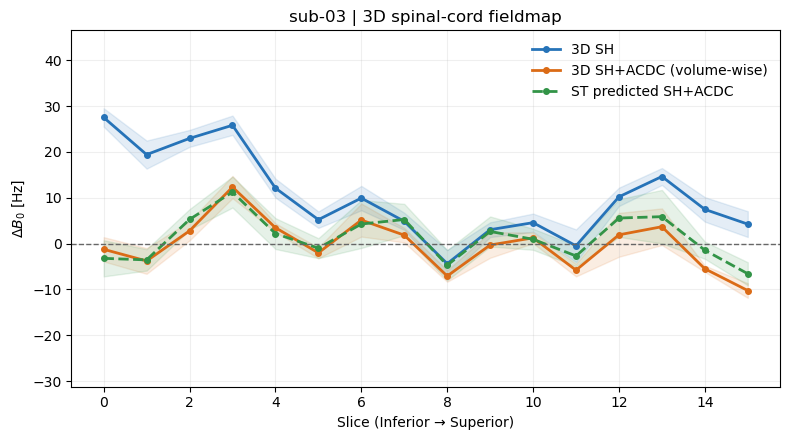

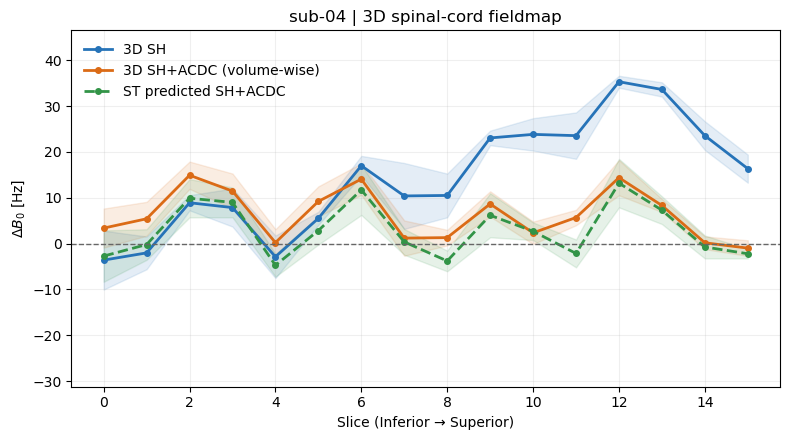

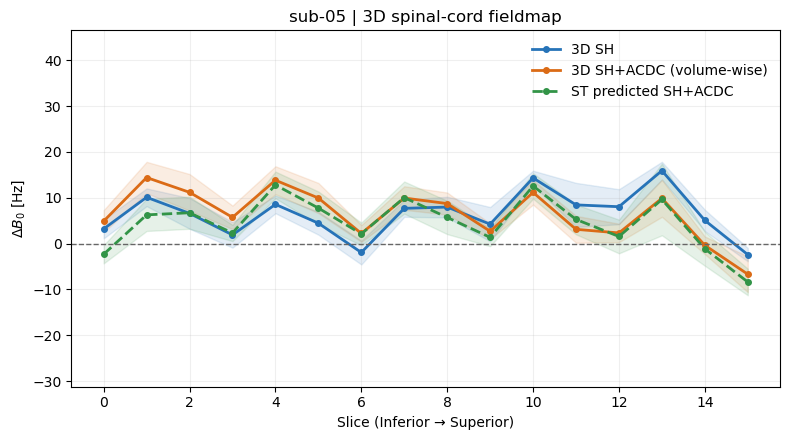

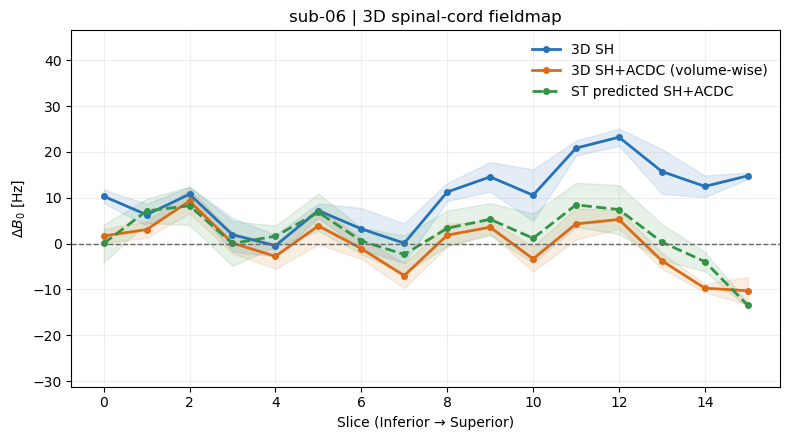

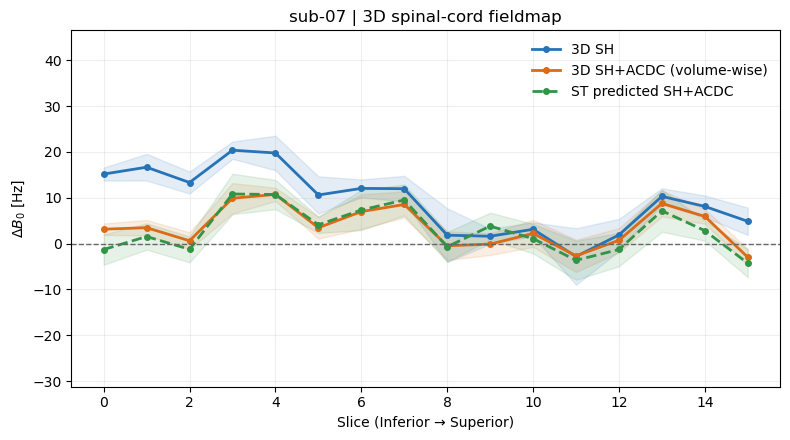

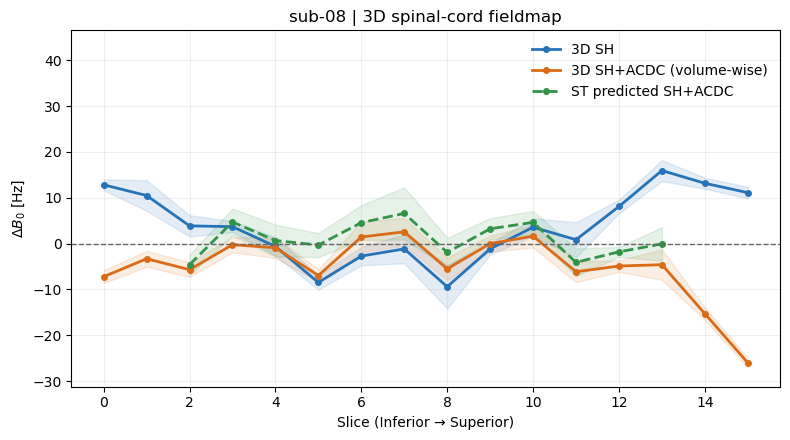

In [7]:
styles = {
    "sh": {
        "label": "3D SH",
        "color": "#2673b8",
        "linestyle": "-",
    },
    "sh_acdc": {
        "label": "3D SH+ACDC (volume-wise)",
        "color": "#db6b16",
        "linestyle": "-",
    },
    "predicted_sh_acdc": {
        "label": "ST predicted SH+ACDC",
        "color": "#329447",
        "linestyle": "--",
    },
}

if not SHOW_PREDICTED:
    styles.pop("predicted_sh_acdc")

slice_col = "Slice (I->S)"
std_col = "STD()"

data_3d = {}
extents = []

for participant_id, conditions in participants.items():
    data_3d[participant_id] = {}

    for condition in styles:
        csv_path = conditions.get(condition, {}).get("b0_csv_path", "")

        if not csv_path or not Path(csv_path).is_file():
            raise FileNotFoundError(
                f"{participant_id}, {condition}: {csv_path!r}"
            )

        frame = pd.read_csv(csv_path)

        mean_col = next(
            (column for column in ("BIN()", "WA()") if column in frame),
            None,
        )

        if mean_col is None:
            raise ValueError(
                f"{participant_id}, {condition}: missing BIN()/WA()"
            )

        required = [slice_col, mean_col, std_col]
        missing = [column for column in required if column not in frame]

        if missing:
            raise ValueError(
                f"{participant_id}, {condition}: missing columns {missing}"
            )

        frame = (
            frame[required]
            .rename(columns={
                slice_col: "Slice",
                mean_col: "Mean",
                std_col: "SD",
            })
            .apply(pd.to_numeric, errors="raise")
            .sort_values("Slice")
            .reset_index(drop=True)
        )

        if frame.empty or not np.isfinite(frame["Slice"]).all():
            raise ValueError(
                f"{participant_id}, {condition}: empty/invalid slice indices"
            )

        if frame["Slice"].duplicated().any() or (frame["SD"] < 0).any():
            raise ValueError(
                f"{participant_id}, {condition}: duplicate slices/negative SD"
            )

        valid = np.isfinite(frame[["Mean", "SD"]]).all(axis=1)

        if not valid.any():
            raise ValueError(
                f"{participant_id}, {condition}: no finite metrics"
            )

        if not valid.all():
            print(
                f"{participant_id}, {condition}: no metrics on slices "
                f"{frame.loc[~valid, 'Slice'].tolist()}; shown as gaps"
            )
            frame.loc[~valid, ["Mean", "SD"]] = np.nan

        data_3d[participant_id][condition] = frame

        extents.extend([
            float((frame["Mean"] - frame["SD"]).min()),
            float((frame["Mean"] + frame["SD"]).max()),
        ])

# Use the same vertical scale across all participants and conditions.
low = min(0.0, min(extents))
high = max(0.0, max(extents))
padding = max(1.0, 0.06 * (high - low))

figures_3d = {}

for participant_id, conditions in data_3d.items():
    fig, ax = plt.subplots(figsize=(8, 4.5))

    for condition, style in styles.items():
        frame = conditions[condition]

        x = frame["Slice"].to_numpy()
        mean = frame["Mean"].to_numpy()
        sd = frame["SD"].to_numpy()

        ax.plot(
            x,
            mean,
            color=style["color"],
            linestyle=style["linestyle"],
            marker="o",
            markersize=4,
            linewidth=2,
            label=style["label"],
        )

        ax.fill_between(
            x,
            mean - sd,
            mean + sd,
            color=style["color"],
            alpha=0.12,
        )

    ax.axhline(0, color="0.4", linestyle="--", linewidth=1)

    ax.set(
        title=f"{participant_id} | 3D spinal-cord fieldmap",
        xlabel="Slice (Inferior → Superior)",
        ylabel=r"$\Delta B_0$ [Hz]",
        ylim=(low - padding, high + padding),
    )

    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    fig.tight_layout()

    figures_3d[participant_id] = fig
    plt.show()


## 2. Three-dimensional vertebral-level fieldmaps
Metrics use exact SC-mask and vertebral-label intersections. Each violin summarizes participant-level values, not pooled voxels.


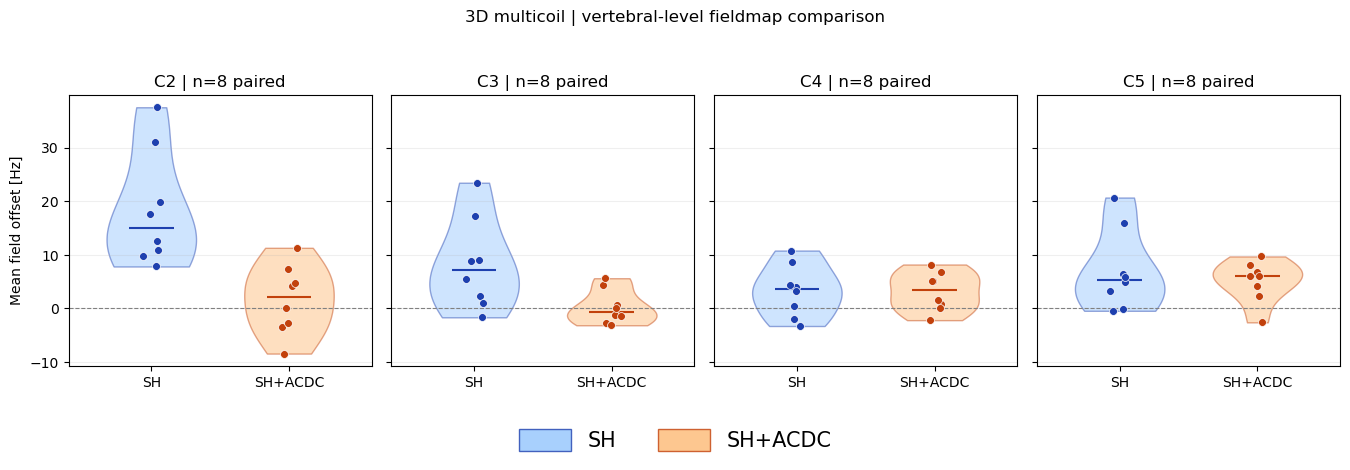

,Participant,Condition,VertLevel,Mean,SD,Nvox,RMSE
0,sub-01,sh,2,37.562,3.252,688,37.702
1,sub-01,sh,3,17.179,5.664,1035,18.089
2,sub-01,sh,4,-1.965,5.579,1488,5.915
3,sub-01,sh,5,-0.146,1.555,758,1.562
4,sub-01,sh_acdc,2,-3.508,2.664,691,4.405
...,...,...,...,...,...,...,...
59,sub-08,sh,5,5.850,3.923,1273,7.043
60,sub-08,sh_acdc,2,-8.436,5.492,1078,10.066
61,sub-08,sh_acdc,3,-1.462,3.990,1080,4.249
62,sub-08,sh_acdc,4,-2.194,4.946,1582,5.411


In [8]:
vertebral_fieldmap_df = calculate_vertebral_metrics(
    participants_3d, "b0_path", "sc_mask_path", VERT_LEVELS)
field_ylabels = {"Mean": "Mean field offset [Hz]", "SD": "Spatial field SD [Hz]",
                 "RMSE": "Field RMSE relative to zero [Hz]"}
fig_vertebral_fieldmap, axes_vertebral_fieldmap = plot_vertebral_violins(
    vertebral_fieldmap_df, FIELDMAP_METRIC,
    "3D multicoil | vertebral-level fieldmap comparison",
    field_ylabels[FIELDMAP_METRIC], levels=VERT_LEVELS,
    show_legend=SHOW_CONDITION_LEGEND)
display(vertebral_fieldmap_df.round(3))


## 3. Whole-volume B0 measurements
Load each selected acquisition once to calculate both spatial SD and MSE. MSE measures error relative to TARGET_B0; SD measures spatial spread about the acquisition mean.


In [10]:
b0_rows, b0_issues = [], []
for dimension, participant_ids in INCLUDED_PARTICIPANTS.items():
    participant_group = participants_by_dimension[dimension]
    for participant_id in participant_ids:
        for condition in MEASURED_CONDITIONS:
            paths = participant_group.get(participant_id, {}).get(condition, {})
            try:
                image, mask = load_aligned_images(paths, ("b0_path", "sc_mask_path"))
            except FileNotFoundError as error:
                b0_issues.append({"Participant": participant_id, "Dimension": dimension,
                                  "Condition": condition, "Issue": str(error)})
                continue
            values = masked_values(image, mask)
            if values.size < 2:
                raise ValueError(f"{participant_id}, {dimension}, {condition}: insufficient SC voxels")
            b0_rows.append({"Participant": participant_id, "Dimension": dimension,
                            "Condition": condition, "B0 Mean": values.mean(),
                            "B0 SD": values.std(ddof=0),
                            "MSE": np.mean((values - TARGET_B0)**2), "Nvox": values.size})

b0_metrics_df = pd.DataFrame(b0_rows, columns=[
    "Participant", "Dimension", "Condition", "B0 Mean", "B0 SD", "MSE", "Nvox"])
b0_sd_df = b0_metrics_df[["Participant", "Dimension", "Condition", "B0 SD", "Nvox"]].copy()
b0_sd_issues_df = pd.DataFrame(b0_issues)
display(b0_metrics_df.round(4))
if not b0_sd_issues_df.empty:
    display(b0_sd_issues_df)

# Build the existing 3D MSE summary from the same measurements.
frame_3d = b0_metrics_df.loc[b0_metrics_df.Dimension == "3D"]
paired_mse = paired_conditions(frame_3d, "MSE")
paired_nvox = paired_conditions(frame_3d, "Nvox")
mse_df = pd.DataFrame({
    "SH MSE": paired_mse["sh"], "SH+ACDC MSE": paired_mse["sh_acdc"],
    "MSE Reduction (%)": 100 * (paired_mse["sh"] - paired_mse["sh_acdc"])
                         / paired_mse["sh"].replace(0, np.nan),
    "SH Nvox": paired_nvox["sh"], "SH+ACDC Nvox": paired_nvox["sh_acdc"],
}).rename_axis("Participant").reset_index()
display(mse_df.round(3))


,Participant,Dimension,Condition,B0 Mean,B0 SD,MSE,Nvox
0,sub-05,2D,sh,10.6876,14.4128,321.9538,6291
1,sub-05,2D,sh_acdc,2.6780,6.2807,46.6188,6468
2,sub-06,2D,sh,10.5932,6.0329,148.6112,7233
3,sub-06,2D,sh_acdc,0.9756,6.0782,37.8960,6938
4,sub-08,2D,sh,4.8102,7.0423,72.7313,7304
5,sub-08,2D,sh_acdc,-1.8134,3.5385,15.8095,7304
6,sub-01,3D,sh,9.1064,13.9828,278.4459,5816
7,sub-01,3D,sh_acdc,3.0720,5.5781,40.5518,5236
8,sub-02,3D,sh,5.5986,9.0398,113.0625,5731
9,sub-02,3D,sh_acdc,-2.3497,7.2791,58.5071,5681


,Participant,SH MSE,SH+ACDC MSE,MSE Reduction (%),SH Nvox,SH+ACDC Nvox
0,sub-01,278.446,40.552,85.436,5816,5236
1,sub-02,113.063,58.507,48.252,5731,5681
2,sub-03,214.470,35.347,83.519,5865,5871
3,sub-04,330.117,80.740,75.542,5878,5500
4,sub-05,70.326,83.073,-18.126,5807,6076
5,sub-06,154.667,34.673,77.582,6522,6603
6,sub-08,73.415,78.076,-6.348,6090,6229


In [11]:
SUBJECT_LINEWIDTH = 0.8
SUBJECT_MARKERSIZE = 6

MEAN_LINEWIDTH = 4
MEAN_MARKERSIZE = 10

OTHER_PARTICIPANT_COLOR = "#999999"


def trajectory_legend_handles(
    participant_ids,
    highlighted_ids,
    show_mean=True,
):
    handles = []

    for participant_id in sorted(set(participant_ids)):
        style = PARTICIPANT_STYLES[participant_id]

        color = (
            style["color"]
            if participant_id in highlighted_ids
            else OTHER_PARTICIPANT_COLOR
        )

        handles.append(
            Line2D(
                [], [],
                color=color,
                marker=style["marker"],
                linewidth=SUBJECT_LINEWIDTH,
                markersize=7,
                markeredgecolor="white",
                markeredgewidth=0.5,
                label=participant_id,
            )
        )

    if show_mean:
        handles.append(
            Line2D(
                [], [],
                color="#111111",
                marker="s",
                linewidth=MEAN_LINEWIDTH,
                markersize=MEAN_MARKERSIZE,
                markeredgecolor="white",
                markeredgewidth=0.8,
                label="Group mean",
            )
        )

    return handles

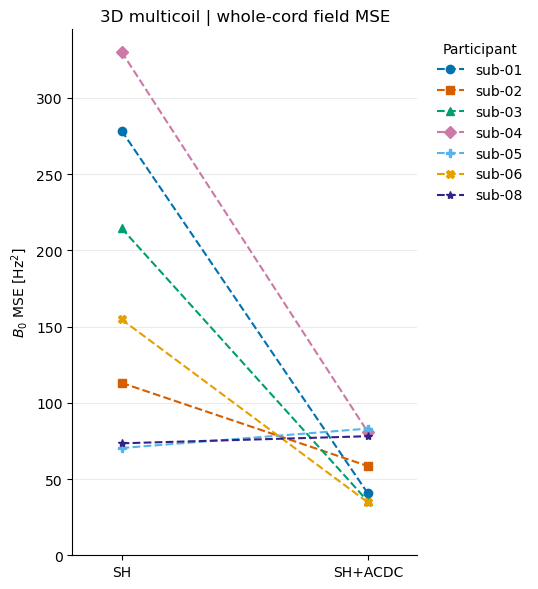

In [12]:
fig_mse, ax_mse = plt.subplots(figsize=(5.5, 6))
for _, row in mse_df.iterrows():
    style = PARTICIPANT_STYLES[row["Participant"]]
    ax_mse.plot([0, 1], [row["SH MSE"], row["SH+ACDC MSE"]],
                color=style["color"], marker=style["marker"], linestyle="--",
                linewidth=1.5, markersize=6, label=row["Participant"])
ax_mse.set_xticks([0, 1], ["SH", "SH+ACDC"])
ax_mse.set(xlim=(-0.2, 1.2), ylim=(0, None),
           ylabel=r"$B_0$ MSE [Hz$^2$]", title="3D multicoil | whole-cord field MSE")
ax_mse.legend(title="Participant", frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
ax_mse.grid(axis="y", alpha=0.25)
ax_mse.spines[["top", "right"]].set_visible(False)
fig_mse.tight_layout()
plt.show()


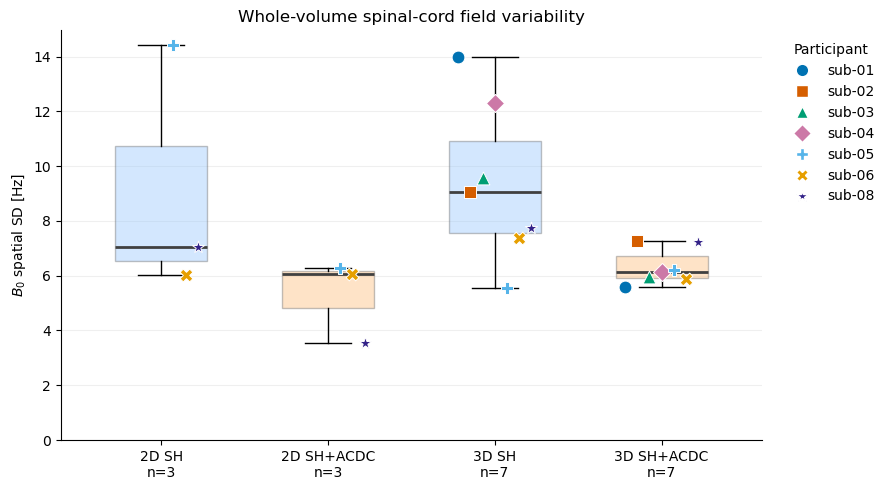

In [13]:
fig_b0_sd, ax_b0_sd = plot_participant_boxes(
    b0_sd_df, value_col="B0 SD", title="Whole-volume spinal-cord field variability",
    ylabel=r"$B_0$ spatial SD [Hz]", figsize=BOX_FIGSIZE)


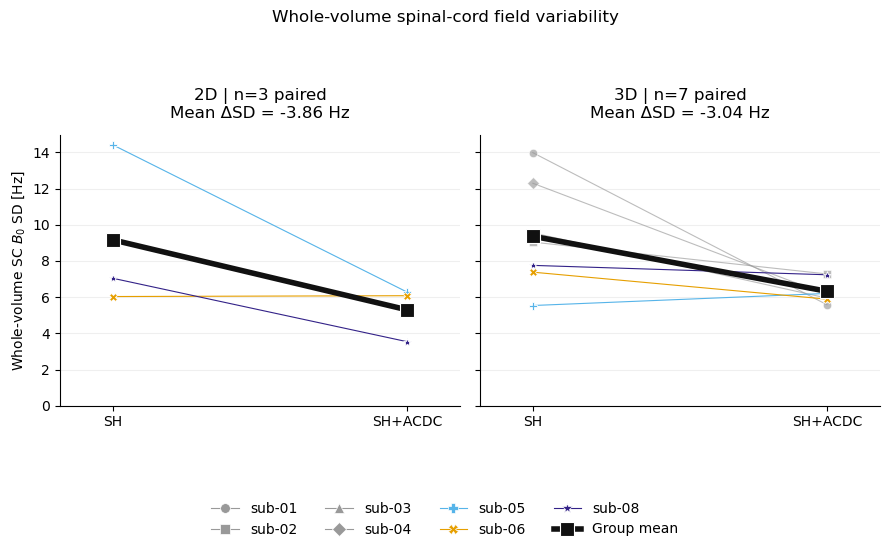

,Dimension,N paired,Mean SH SD [Hz],Mean SH+ACDC SD [Hz],Mean SD reduction [Hz]
0,2D,3,9.1626,5.2991,-3.8635
1,3D,7,9.3624,6.3229,-3.0396


In [38]:
# ============================================================
# Whole-volume B0 SD: paired participant trajectories
# ============================================================

paired_sd = {}

for dimension in ("2D", "3D"):
    selected = b0_sd_df.loc[
        (b0_sd_df["Dimension"] == dimension)
        & b0_sd_df["Participant"].isin(
            INCLUDED_PARTICIPANTS[dimension]
        )
    ]

    paired_sd[dimension] = paired_conditions(
        selected,
        "B0 SD",
    )

# Participants present in the 2D analysis retain their colours.
highlighted_participants = set(paired_sd["2D"].index)

fig_b0_sd, axes_b0_sd = plt.subplots(
    1, 2,
    figsize=(9, 5.5),
    sharey=True,
)

change_rows = []

for ax, dimension in zip(axes_b0_sd, ("2D", "3D")):
    paired = paired_sd[dimension]

    # Draw gray participants first so coloured lines remain visible.
    plot_order = sorted(
        paired.index,
        key=lambda participant_id: (
            participant_id in highlighted_participants,
            participant_id,
        ),
    )

    for participant_id in plot_order:
        style = PARTICIPANT_STYLES[participant_id]
        highlighted = participant_id in highlighted_participants

        color = style["color"] if highlighted else "#999999"

        ax.plot(
            [0, 1],
            [
                paired.loc[participant_id, "sh"],
                paired.loc[participant_id, "sh_acdc"],
            ],
            color=color,
            marker=style["marker"],
            linewidth=SUBJECT_LINEWIDTH,
            markersize=SUBJECT_MARKERSIZE,
            alpha=1.0 if highlighted else 0.65,
            markeredgecolor="white",
            markeredgewidth=0.6,
            zorder=3 if highlighted else 2,
        )

    n = len(paired)

    sh_mean = paired["sh"].mean()
    acdc_mean = paired["sh_acdc"].mean()
    delta_sd = acdc_mean - sh_mean

    if n:
        ax.plot(
            [0, 1],
            [sh_mean, acdc_mean],
            color="#111111",
            marker="s",
            markersize=MEAN_MARKERSIZE,
            linewidth=MEAN_LINEWIDTH,
            markeredgecolor="white",
            markeredgewidth=0.8,
            zorder=6,
        )

    change_rows.append({
        "Dimension": dimension,
        "N paired": n,
        "Mean SH SD [Hz]": sh_mean,
        "Mean SH+ACDC SD [Hz]": acdc_mean,
        "Mean SD reduction [Hz]": delta_sd,
    })

    delta_label = (
        f"Mean ΔSD = {delta_sd:+.2f} Hz"
        if n else "No complete pairs"
    )

    ax.set_title(
        f"{dimension} | n={n} paired\n{delta_label}",
        pad=12,
    )

    ax.set_xticks([0, 1], ["SH", "SH+ACDC"])
    ax.set_xlim(-0.18, 1.18)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes_b0_sd[0].set_ylabel(
    r"Whole-volume SC $B_0$ SD [Hz]"
)

all_shown_participants = (
    set(paired_sd["2D"].index)
    | set(paired_sd["3D"].index)
)

handles = trajectory_legend_handles(
    participant_ids=all_shown_participants,
    highlighted_ids=highlighted_participants,
    show_mean=True,
)

fig_b0_sd.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
)

fig_b0_sd.suptitle(
    "Whole-volume spinal-cord field variability",
    y=0.99,
)

fig_b0_sd.tight_layout(rect=[0, 0.20, 1, 0.93])
plt.show()

b0_sd_change_df = pd.DataFrame(change_rows)
display(b0_sd_change_df.round(4))

## 4. Three-dimensional magnitude tissue statistics
Within-tissue spatial mean, SD, and CV from echo-average magnitude images. CV is spatial variability relative to mean intensity, not a direct noise estimate.


In [16]:
magnitude_results = []
for participant_id, conditions in participants_3d.items():
    for condition in MEASURED_CONDITIONS:
        metrics = calculate_tissue_statistics(conditions[condition], "magnitude_path")
        for tissue in ("GM", "WM"):
            mean, sd = metrics[f"{tissue} Mean"], metrics[f"{tissue} SD"]
            cv = sd / mean if mean > 0 else np.nan
            metrics[f"{tissue} CV"] = cv
            metrics[f"{tissue} CV (%)"] = 100 * cv
        magnitude_results.append({"Participant": participant_id,
                                  "Condition": CONDITION_LABELS[condition], **metrics})
magnitude_metrics_df = pd.DataFrame(magnitude_results)
display(magnitude_metrics_df.round(3))
cv_comparison_df = (magnitude_metrics_df.pivot(
    index="Participant", columns="Condition", values=["GM CV (%)", "WM CV (%)"])
    .reindex(columns=pd.MultiIndex.from_product([
        ["GM CV (%)", "WM CV (%)"], ["SH", "SH+ACDC"]])))
display(cv_comparison_df.round(2))


,Participant,Condition,GM Mean,GM SD,GM Nvox,WM Mean,WM SD,WM Nvox,GM CV,GM CV (%),WM CV,WM CV (%)
0,sub-01,SH,59.942,10.753,1060,52.955,10.677,5642,0.179,17.940,0.202,20.162
1,sub-01,SH+ACDC,61.836,6.559,803,56.852,6.944,4436,0.106,10.607,0.122,12.215
2,sub-02,SH,65.124,11.250,972,59.383,10.523,4762,0.173,17.275,0.177,17.720
3,sub-02,SH+ACDC,60.846,9.483,910,55.181,10.465,4771,0.156,15.586,0.190,18.966
4,sub-03,SH,53.446,5.205,1078,46.759,6.083,4789,0.097,9.738,0.130,13.008
5,sub-03,SH+ACDC,52.419,5.271,1012,46.360,6.647,4859,0.101,10.055,0.143,14.337
6,sub-04,SH,57.959,10.207,1029,51.008,10.545,4850,0.176,17.612,0.207,20.673
7,sub-04,SH+ACDC,59.438,8.399,1016,51.934,9.223,4503,0.141,14.130,0.178,17.759
8,sub-05,SH,74.102,10.366,1069,65.809,11.743,4739,0.140,13.988,0.178,17.844
9,sub-05,SH+ACDC,64.344,10.815,1038,57.302,11.136,5040,0.168,16.808,0.194,19.433


GM CV (%)         WM CV (%)        
                   SH SH+ACDC        SH SH+ACDC
Participant                                    
sub-01          17.94   10.61     20.16   12.21
sub-02          17.28   15.59     17.72   18.97
sub-03           9.74   10.06     13.01   14.34
sub-04          17.61   14.13     20.67   17.76
sub-05          13.99   16.81     17.84   19.43
sub-06          10.73   15.78     15.60   19.21
sub-07          14.79   15.05     18.24   17.73
sub-08          12.07   10.90     13.27   12.11

## 5. Three-dimensional dipole inversion
The selected optimized DI method is shared with the susceptibility CNR calculation. Each point is one participant mean within a tissue and vertebral level; the violin bar is the median across participants.


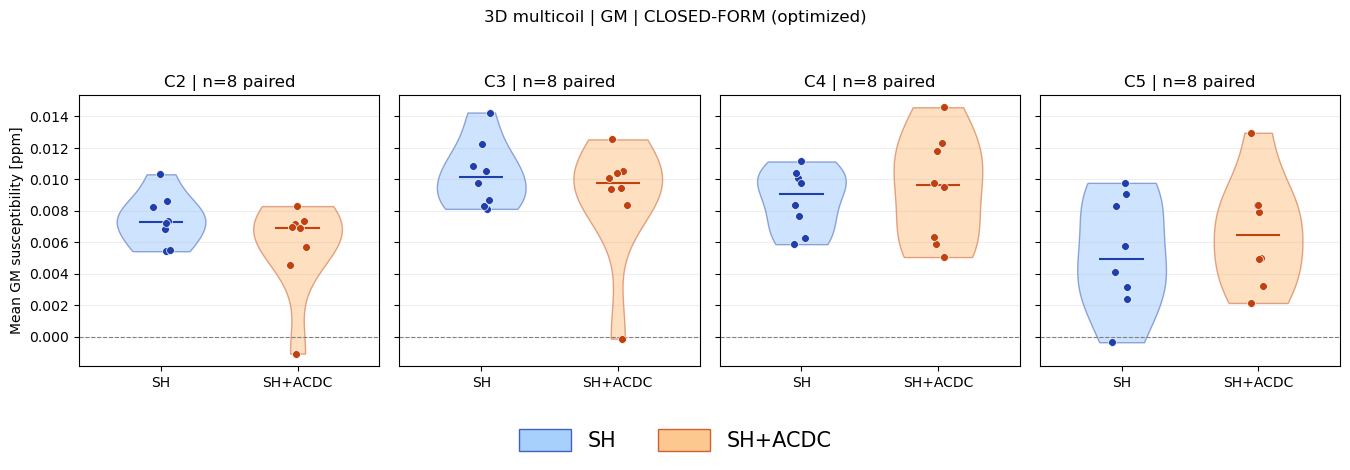

In [17]:
gm_di_metrics_df = calculate_vertebral_metrics(
    participants_3d, DI_KEYS[DI_METHOD], "gm_mask_path", VERT_LEVELS, intersect_sc=True)
gm_di_metrics_df = gm_di_metrics_df.assign(Tissue="GM", Method=DI_LABELS[DI_METHOD])
gm_di_fig, gm_di_axes = plot_vertebral_violins(
    gm_di_metrics_df, "Mean", f"3D multicoil | GM | {DI_LABELS[DI_METHOD]} (optimized)",
    "Mean GM susceptibility [ppm]", levels=VERT_LEVELS,
    show_legend=SHOW_CONDITION_LEGEND)


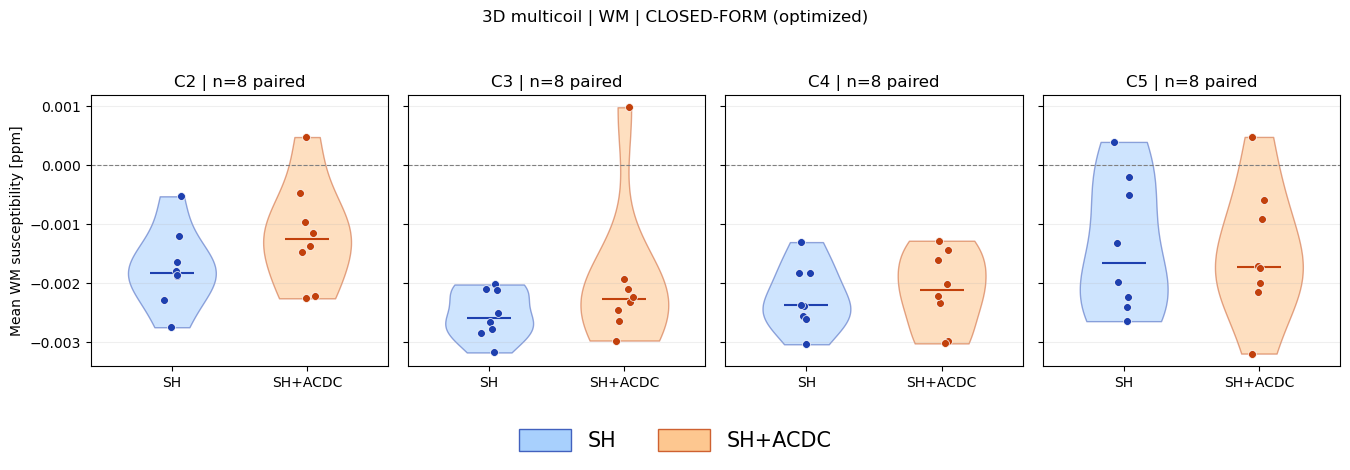

In [18]:
wm_di_metrics_df = calculate_vertebral_metrics(
    participants_3d, DI_KEYS[DI_METHOD], "wm_mask_path", VERT_LEVELS, intersect_sc=True)
wm_di_metrics_df = wm_di_metrics_df.assign(Tissue="WM", Method=DI_LABELS[DI_METHOD])
wm_di_fig, wm_di_axes = plot_vertebral_violins(
    wm_di_metrics_df, "Mean", f"3D multicoil | WM | {DI_LABELS[DI_METHOD]} (optimized)",
    "Mean WM susceptibility [ppm]", levels=VERT_LEVELS,
    show_legend=SHOW_CONDITION_LEGEND)

di_check_df = pd.concat([gm_di_metrics_df, wm_di_metrics_df], ignore_index=True)
if SHOW_DI_C2_C3_TABLE:
    display(di_check_df.loc[di_check_df.VertLevel.isin([2, 3])]
            .sort_values(["Participant", "Tissue", "VertLevel", "Condition"]).round(6))


## 6. Whole-volume local-field and susceptibility CNR

One CNR is calculated per acquisition by pooling GM and WM voxels across all slices:

\[
\mathrm{CNR}=\frac{|\mu_{GM}-\mu_{WM}|}
{\sqrt{(SD_{GM}^{2}+SD_{WM}^{2})/2}}.
\]

Both calculation and plotting use `INCLUDED_PARTICIPANTS` above. This replaces the
previous separate lowercase participant-selection dictionary. The settings preserve
the original notebook's current GM/WM overlap behavior; masks are not altered here.


In [19]:
outcomes = {
    "Local field": {"image_key": "localfield_optpdf_path", "label": "Local field | OPT PDF"},
    "Susceptibility": {"image_key": DI_KEYS[DI_METHOD],
                       "label": f"Susceptibility | {DI_LABELS[DI_METHOD]} (optimized)"},
}
cnr_results, cnr_issues = [], []
for outcome, settings in outcomes.items():
    for dimension, participant_ids in INCLUDED_PARTICIPANTS.items():
        participant_group = participants_by_dimension[dimension]
        for participant_id in participant_ids:
            for condition in MEASURED_CONDITIONS:
                paths = participant_group.get(participant_id, {}).get(condition, {})
                try:
                    metrics = calculate_whole_cnr(paths, settings["image_key"])
                except FileNotFoundError as error:
                    cnr_issues.append({"Outcome": outcome, "Participant": participant_id,
                                       "Dimension": dimension, "Condition": condition,
                                       "Issue": str(error)})
                    continue
                except ValueError as error:
                    raise ValueError(f"{outcome}, {participant_id}, {dimension}, {condition}: {error}") from error
                cnr_results.append({"Outcome": outcome, "Participant": participant_id,
                                    "Dimension": dimension, "Condition": condition, **metrics})
cnr_df = pd.DataFrame(cnr_results, columns=[
    "Outcome", "Participant", "Dimension", "Condition", "GM Mean", "WM Mean",
    "GM SD", "WM SD", "GM Nvox", "WM Nvox", "CNR"])
cnr_issues_df = pd.DataFrame(cnr_issues, columns=[
    "Outcome", "Participant", "Dimension", "Condition", "Issue"])
display(cnr_df.round(4))
display(cnr_issues_df)


,Outcome,Participant,Dimension,Condition,GM Mean,WM Mean,GM SD,WM SD,GM Nvox,WM Nvox,CNR
0,Local field,sub-05,2D,sh,0.2349,-0.0625,0.5880,0.5859,1060,5244,0.5067
1,Local field,sub-05,2D,sh_acdc,0.2637,-0.0904,0.6333,0.6446,1094,5374,0.5542
2,Local field,sub-06,2D,sh,0.2873,-0.1127,0.8610,1.2416,1225,5723,0.3744
3,Local field,sub-06,2D,sh_acdc,0.1764,-0.0391,0.8535,0.9069,1253,5691,0.2448
4,Local field,sub-08,2D,sh,0.3207,-0.0807,0.7764,0.8142,1238,6072,0.5046
5,Local field,sub-08,2D,sh_acdc,0.0954,-0.0465,0.7293,0.6934,1238,6072,0.1994
6,Local field,sub-01,3D,sh,0.4025,-0.1010,0.5127,0.4749,1060,5642,1.0189
7,Local field,sub-01,3D,sh_acdc,0.4345,-0.1098,0.5379,0.4200,803,4436,1.1280
8,Local field,sub-02,3D,sh,0.3712,-0.0982,0.4945,0.4071,972,4762,1.0364
9,Local field,sub-02,3D,sh_acdc,0.4544,-0.1140,0.5507,0.4404,910,4771,1.1399


,Outcome,Participant,Dimension,Condition,Issue


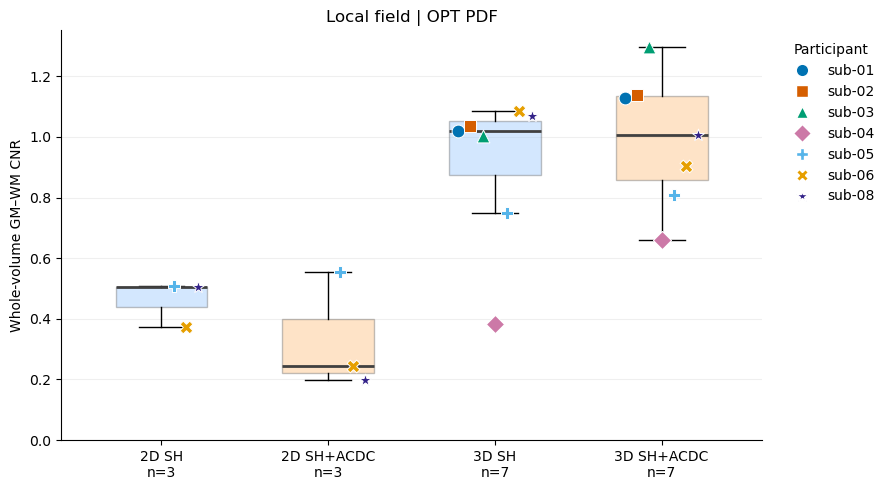

In [20]:
localfield_cnr_df = cnr_df.loc[
    cnr_df["Outcome"] == "Local field"
].copy()

fig_localfield_cnr, ax_localfield_cnr = plot_participant_boxes(
    localfield_cnr_df,
    value_col="CNR",
    title="Local field | OPT PDF",
    ylabel="Whole-volume GM–WM CNR",
    figsize=BOX_FIGSIZE,
)


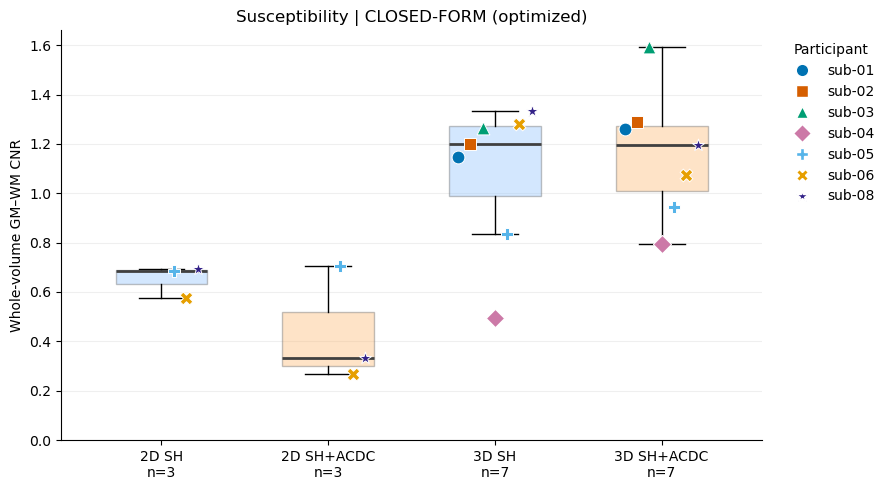

In [21]:
susceptibility_cnr_df = cnr_df.loc[
    cnr_df["Outcome"] == "Susceptibility"
].copy()

method_label = {
    "closedform": "CLOSED-FORM",
    "medi": "MEDI",
    "fansi": "FANSI",
}[DI_METHOD]

fig_susceptibility_cnr, ax_susceptibility_cnr = (
    plot_participant_boxes(
        susceptibility_cnr_df,
        value_col="CNR",
        title=f"Susceptibility | {method_label} (optimized)",
        ylabel="Whole-volume GM–WM CNR",
        figsize=BOX_FIGSIZE,
    )
)


In [22]:
SHOW_CNR_MEAN = True  # Dark line connecting group means.


def get_cnr_pairs(outcome, dimension):
    selected = cnr_df.loc[
        (cnr_df["Outcome"] == outcome)
        & (cnr_df["Dimension"] == dimension)
        & cnr_df["Participant"].isin(
            INCLUDED_PARTICIPANTS[dimension]
        )
    ]
    return paired_conditions(selected, "CNR")


def cnr_row_limits(outcome):
    values = np.concatenate([
        get_cnr_pairs(outcome, dimension).to_numpy().ravel()
        for dimension in ("2D", "3D")
    ])

    values = values[np.isfinite(values)]
    maximum = values.max() if len(values) else 1.0

    return (0, max(maximum * 1.15, 1e-6))


def cnr_legend_handles(participant_ids):
    return trajectory_legend_handles(
        participant_ids=participant_ids,
        highlighted_ids=set(INCLUDED_PARTICIPANTS["2D"]),
        show_mean=SHOW_CNR_MEAN,
    )


def plot_cnr_panel(
    outcome,
    dimension,
    ax=None,
    figsize=(4.8, 5),
    ylim=None,
):
    standalone = ax is None

    if standalone:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    paired = get_cnr_pairs(outcome, dimension)
    highlighted = set(INCLUDED_PARTICIPANTS["2D"])

    plot_order = sorted(
        paired.index,
        key=lambda p: (p in highlighted, p),
    )

    # Fine participant lines.
    for participant_id in plot_order:
        style = PARTICIPANT_STYLES[participant_id]
        use_color = participant_id in highlighted

        ax.plot(
            [0, 1],
            paired.loc[
                participant_id, ["sh", "sh_acdc"]
            ].to_numpy(),
            color=(
                style["color"]
                if use_color else OTHER_PARTICIPANT_COLOR
            ),
            marker=style["marker"],
            linewidth=SUBJECT_LINEWIDTH,
            markersize=SUBJECT_MARKERSIZE,
            alpha=1.0 if use_color else 0.65,
            markeredgecolor="white",
            markeredgewidth=0.6,
            zorder=3 if use_color else 2,
        )

    # Bold group-mean line.
    if SHOW_CNR_MEAN and len(paired):
        ax.plot(
            [0, 1],
            paired[["sh", "sh_acdc"]].mean().to_numpy(),
            color="#111111",
            marker="s",
            linewidth=MEAN_LINEWIDTH,
            markersize=MEAN_MARKERSIZE,
            markeredgecolor="white",
            markeredgewidth=0.8,
            zorder=6,
        )

    if paired.empty:
        ax.text(
            0.5, 0.5,
            "No complete pairs",
            ha="center",
            transform=ax.transAxes,
        )

    if len(paired):
        delta_cnr = (
            paired["sh_acdc"] - paired["sh"]
        ).mean()

        delta_label = f"Mean ΔCNR = {delta_cnr:+.3f}"
    else:
        delta_label = "No complete pairs"

    ax.set_title(
        f"{outcomes[outcome]['label']}\n"
        f"{dimension} | n={len(paired)} paired\n"
        f"{delta_label}"
)

    ax.set_xticks([0, 1], ["SH", "SH+ACDC"])
    ax.set_xlim(-0.18, 1.18)
    ax.set_ylim(
        ylim if ylim is not None else cnr_row_limits(outcome)
    )
    ax.set_ylabel("Whole-volume GM–WM CNR")

    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if standalone:
        handles = cnr_legend_handles(paired.index)

        if handles:
            fig.legend(
                handles=handles,
                loc="lower center",
                ncol=2,
                frameon=False,
            )

        fig.tight_layout(rect=[0, 0.28, 1, 1])
        plt.show()

    return fig, ax

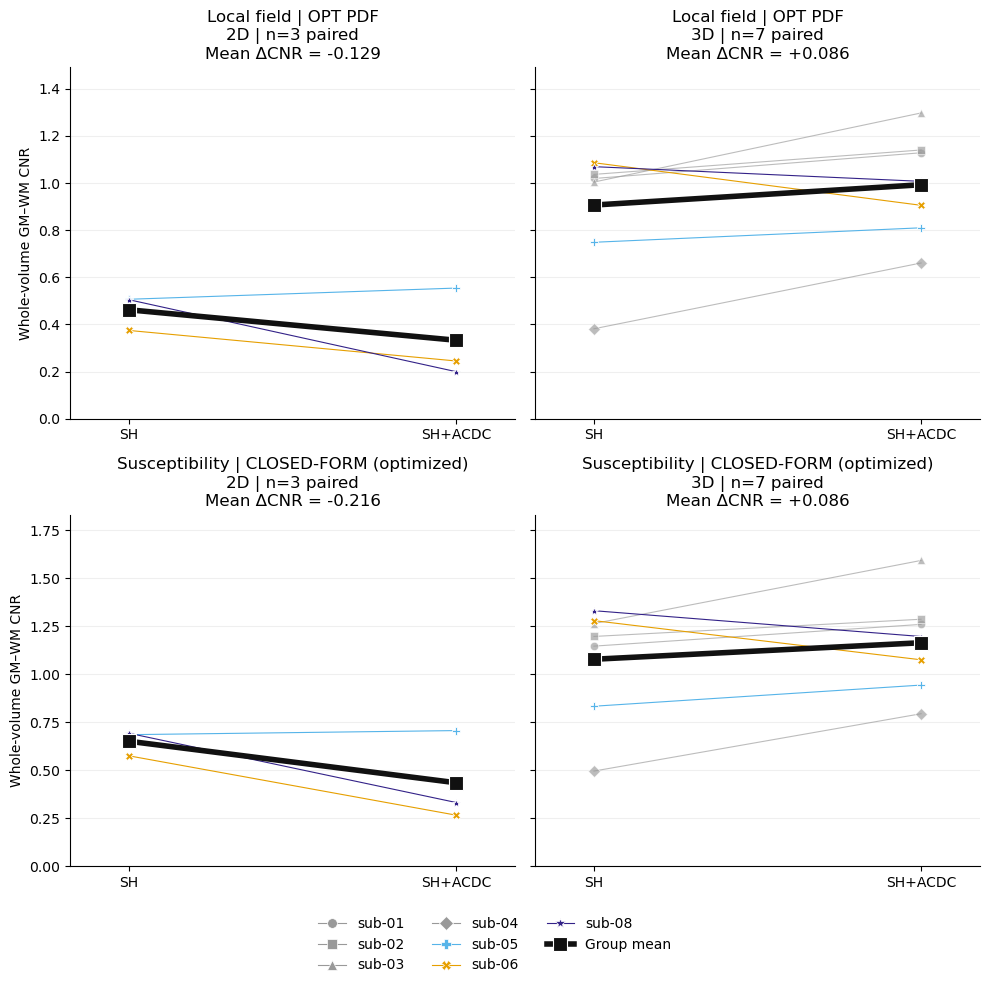

In [23]:
fig_cnr_combined, axes_cnr_combined = plt.subplots(
    2, 2,
    figsize=(10, 10),
    sharey="row",
)

panel_settings = [
    ("Local field", "2D"),
    ("Local field", "3D"),
    ("Susceptibility", "2D"),
    ("Susceptibility", "3D"),
]

shown_participants = set()

for ax, (outcome, dimension) in zip(
    axes_cnr_combined.ravel(),
    panel_settings,
):
    plot_cnr_panel(
        outcome,
        dimension,
        ax=ax,
    )

    shown_participants.update(
        get_cnr_pairs(outcome, dimension).index
    )

# Only the left panels need y-axis labels.
axes_cnr_combined[0, 1].set_ylabel("")
axes_cnr_combined[1, 1].set_ylabel("")

handles = cnr_legend_handles(shown_participants)

if handles:
    fig_cnr_combined.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=3,
        frameon=False,
    )

fig_cnr_combined.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# Optional:
# fig_cnr_combined.savefig(
#     "CNR_localfield_susceptibility.png",
#     dpi=300,
#     bbox_inches="tight",
# )

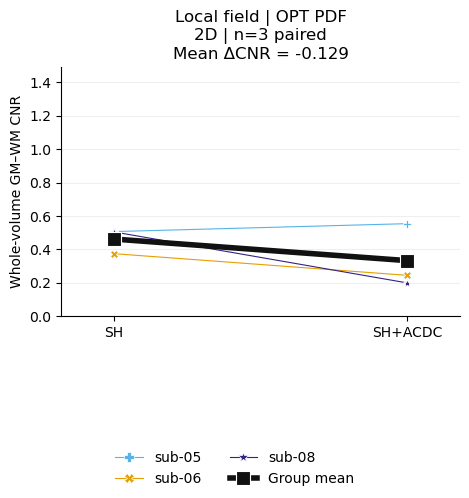

In [25]:
fig_lf_2d, ax_lf_2d = plot_cnr_panel(
    "Local field", "2D", figsize=(4.8, 5)
)

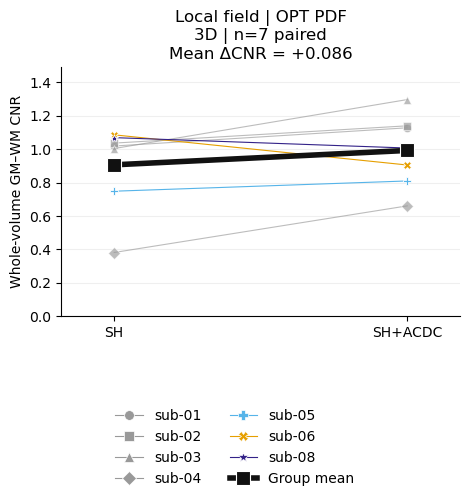

In [26]:
fig_lf_3d, ax_lf_3d = plot_cnr_panel(
    "Local field", "3D", figsize=(4.8, 5)
)

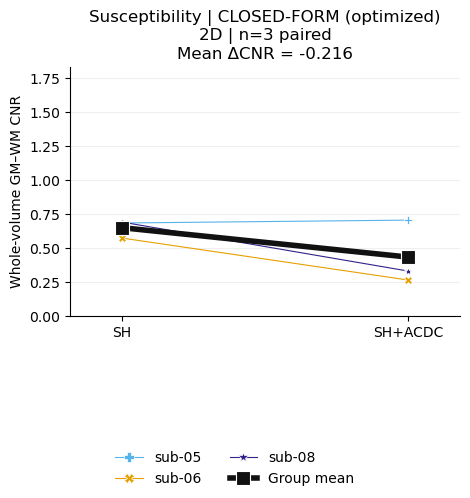

In [27]:
fig_chi_2d, ax_chi_2d = plot_cnr_panel(
    "Susceptibility", "2D", figsize=(4.8, 5)
)

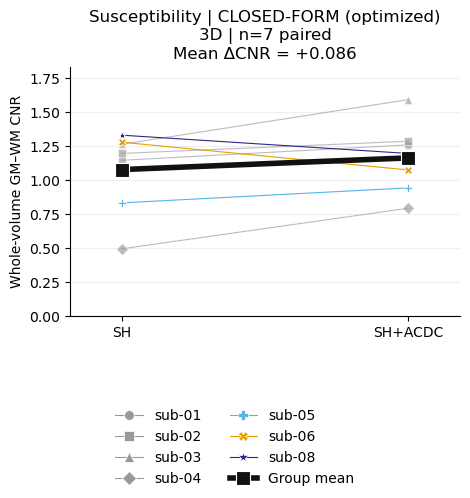

In [28]:
fig_chi_3d, ax_chi_3d = plot_cnr_panel(
    "Susceptibility", "3D", figsize=(4.8, 5)
)

## 7. Exploratory paired tests

All tests are paired, two-sided t-tests on participant-level measurements, with raw
unadjusted p-values and 95% confidence intervals. The paired differences should be
approximately normally distributed, with independent participants. Non-significance
does not establish equivalence. A positive `Difference (after-before)` means the
second argument to the helper is larger.


In [29]:
# Whole-volume B0 SD: negative differences indicate lower SD after ACDC.
rows = []
for dimension in ("2D", "3D"):
    paired = paired_conditions(b0_sd_df.loc[b0_sd_df.Dimension == dimension], "B0 SD")
    rows.append({"Dimension": dimension, "Metric": "B0 spatial SD [Hz]",
                 **paired_test_summary(paired["sh"], paired["sh_acdc"])})
b0_sd_ttests_df = pd.DataFrame(rows)
display(b0_sd_ttests_df.round(6))


,Dimension,Metric,N paired,Before average,After average,Difference (after-before),Difference CI95 low,Difference CI95 high,t statistic,p raw (two-sided)
0,2D,B0 spatial SD [Hz],3,9.162647,5.299133,-3.863514,-14.049859,6.322831,-1.631926,0.244283
1,3D,B0 spatial SD [Hz],7,9.362428,6.322859,-3.039570,-6.035770,-0.043369,-2.482330,0.047655


In [30]:
# CNR: positive differences indicate higher CNR after ACDC.
rows = []
for outcome in outcomes:
    for dimension in ("2D", "3D"):
        frame = cnr_df.loc[(cnr_df.Outcome == outcome) & (cnr_df.Dimension == dimension)]
        paired = paired_conditions(frame, "CNR")
        rows.append({"Outcome": outcome, "Dimension": dimension,
                     **paired_test_summary(paired["sh"], paired["sh_acdc"])})
cnr_ttest_df = pd.DataFrame(rows)
display(cnr_ttest_df.round(6))


,Outcome,Dimension,N paired,Before average,After average,Difference (after-before),Difference CI95 low,Difference CI95 high,t statistic,p raw (two-sided)
0,Local field,2D,3,0.461879,0.332799,-0.129080,-0.567100,0.308940,-1.267945,0.332446
1,Local field,3D,7,0.906297,0.992492,0.086194,-0.071647,0.244036,1.336210,0.229923
2,Susceptibility,2D,3,0.651260,0.434941,-0.216319,-0.731542,0.298904,-1.806490,0.212588
3,Susceptibility,3D,7,1.078830,1.164883,0.086053,-0.098367,0.270472,1.141765,0.297061


In [32]:
# Cross-dimensional comparisons: use complete four-condition participant sets.
# Differences are 2D minus 3D, including for the ACDC-gain comparison.
rows = []
required_columns = pd.MultiIndex.from_product([["2D", "3D"], list(MEASURED_CONDITIONS)])
for outcome in outcomes:
    frame = cnr_df.loc[cnr_df.Outcome == outcome]
    paired = (frame.pivot(index="Participant", columns=["Dimension", "Condition"], values="CNR")
              .reindex(columns=required_columns).replace([np.inf, -np.inf], np.nan).dropna())
    gain_2d = paired[("2D", "sh_acdc")] - paired[("2D", "sh")]
    gain_3d = paired[("3D", "sh_acdc")] - paired[("3D", "sh")]
    comparisons = {
        "SH: 2D vs 3D": (paired[("3D", "sh")], paired[("2D", "sh")]),
        "SH+ACDC: 2D vs 3D": (paired[("3D", "sh_acdc")], paired[("2D", "sh_acdc")]),
        "ACDC gain: 2D vs 3D": (gain_3d, gain_2d),
    }
    for comparison, (values_3d, values_2d) in comparisons.items():
        summary = paired_test_summary(values_3d, values_2d)
        summary = {({"Before average": "Mean 3D", "After average": "Mean 2D",
                     "Difference (after-before)": "Mean difference (2D-3D)"}.get(key, key)): value
                   for key, value in summary.items()}
        rows.append({"Outcome": outcome, "Comparison": comparison, **summary})
cnr_2d_vs_3d_df = pd.DataFrame(rows)
display(cnr_2d_vs_3d_df.round(6))


,Outcome,Comparison,N paired,Mean 3D,Mean 2D,Mean difference (2D-3D),Difference CI95 low,Difference CI95 high,t statistic,p raw (two-sided)
0,Local field,SH: 2D vs 3D,3,0.967808,0.461879,-0.505930,-1.103010,0.091150,-3.645809,0.067685
1,Local field,SH+ACDC: 2D vs 3D,3,0.907291,0.332799,-0.574492,-1.284408,0.135425,-3.481873,0.073506
2,Local field,ACDC gain: 2D vs 3D,3,-0.060518,-0.129080,-0.068562,-0.452208,0.315084,-0.768935,0.522323
3,Susceptibility,SH: 2D vs 3D,3,1.148665,0.651260,-0.497405,-1.253098,0.258288,-2.832052,0.105344
4,Susceptibility,SH+ACDC: 2D vs 3D,3,1.072503,0.434941,-0.637562,-1.501677,0.226553,-3.174587,0.086540
5,Susceptibility,ACDC gain: 2D vs 3D,3,-0.076162,-0.216319,-0.140157,-0.326813,0.046499,-3.230795,0.083920


In [33]:
# DI tissue metric: SD by default; select Mean in Settings for tissue-mean tests.
rows = []
for tissue, frame in {"GM": gm_di_metrics_df, "WM": wm_di_metrics_df}.items():
    for level in VERT_LEVELS:
        paired = paired_conditions(frame.loc[frame.VertLevel == level], DI_TEST_METRIC)
        rows.append({"Tissue": tissue, "Metric": DI_TEST_METRIC,
                     "Method": DI_LABELS[DI_METHOD], "VertLevel": level,
                     **paired_test_summary(paired["sh"], paired["sh_acdc"])})
di_paired_ttests_df = pd.DataFrame(rows)
display(di_paired_ttests_df.round(6))


,Tissue,Metric,Method,VertLevel,N paired,Before average,After average,Difference (after-before),Difference CI95 low,Difference CI95 high,t statistic,p raw (two-sided)
0,GM,SD,CLOSED-FORM,2,8,0.007512,0.006978,-0.000534,-0.002844,0.001776,-0.546707,0.601564
1,GM,SD,CLOSED-FORM,3,8,0.008217,0.008702,0.000485,-0.001725,0.002694,0.518779,0.619907
2,GM,SD,CLOSED-FORM,4,8,0.008127,0.007893,-0.000234,-0.001500,0.001032,-0.436874,0.675362
3,GM,SD,CLOSED-FORM,5,8,0.008193,0.007691,-0.000501,-0.001826,0.000823,-0.895434,0.400297
4,WM,SD,CLOSED-FORM,2,8,0.006148,0.005426,-0.000722,-0.002538,0.001094,-0.940047,0.378491
5,WM,SD,CLOSED-FORM,3,8,0.007947,0.008634,0.000686,-0.001426,0.002798,0.768068,0.467561
6,WM,SD,CLOSED-FORM,4,8,0.009223,0.009223,0.000001,-0.001806,0.001807,0.000667,0.999486
7,WM,SD,CLOSED-FORM,5,8,0.008888,0.007788,-0.001101,-0.002787,0.000585,-1.543825,0.166542


## 8. Final summary

In [34]:
from IPython.display import display, Markdown

ALPHA = 0.05
CNR_DECIMALS = 3

method_label = DI_LABELS[DI_METHOD]

stage_labels = {
    "Local field": "B0loc (OPT PDF)",
    "Susceptibility": f"susceptibility ({method_label})",
}

dimension_labels = {
    "2D": "2D slice-wise ACDC shimming",
    "3D": "3D volume-wise ACDC shimming",
}


def format_p(p):
    if not np.isfinite(p):
        return "p unavailable"
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


summary_rows = []
paragraph_sentences = []

for dimension in ("2D", "3D"):
    clauses = []

    for outcome in ("Local field", "Susceptibility"):
        subset = cnr_df.loc[
            (cnr_df["Dimension"] == dimension)
            & (cnr_df["Outcome"] == outcome)
        ]

        paired = paired_conditions(subset, "CNR")
        test = paired_test_summary(
            paired["sh"],
            paired["sh_acdc"],
        )

        sh_mean = test["Before average"]
        acdc_mean = test["After average"]
        difference = test["Difference (after-before)"]
        p = test["p raw (two-sided)"]
        n = test["N paired"]

        summary_rows.append({
            "Dimension": dimension,
            "Stage": stage_labels[outcome],
            "N paired": n,
            "SH mean CNR": sh_mean,
            "SH+ACDC mean CNR": acdc_mean,
            "Difference (ACDC-SH)": difference,
            "Difference CI95 low": test["Difference CI95 low"],
            "Difference CI95 high": test["Difference CI95 high"],
            "p raw (two-sided)": p,
        })

        if n == 0:
            clauses.append(
                f"no paired {stage_labels[outcome]} CNR data were available"
            )
            continue

        if np.isclose(difference, 0, atol=1e-12, rtol=0):
            direction = "was unchanged"
        elif difference > 0:
            direction = "increased"
        else:
            direction = "decreased"

        significance = (
            "insufficient paired data for testing"
            if not np.isfinite(p)
            else "statistically significant"
            if p < ALPHA
            else "not statistically significant"
        )

        clauses.append(
            f"mean {stage_labels[outcome]} CNR {direction} "
            f"from {sh_mean:.{CNR_DECIMALS}f} with SH "
            f"to {acdc_mean:.{CNR_DECIMALS}f} with SH+ACDC "
            f"({significance}; {format_p(p)}, n = {n})"
        )

    paragraph_sentences.append(
        f"For {dimension_labels[dimension]}, "
        + "; ".join(clauses)
        + "."
    )

cnr_final_summary_df = pd.DataFrame(summary_rows)
cnr_results_paragraph = " ".join(paragraph_sentences)

display(cnr_final_summary_df.round(6))
display(Markdown(cnr_results_paragraph))

print(
    "Tests are paired, two-sided t-tests. "
    "P-values are exploratory and unadjusted for multiple comparisons."
)

,Dimension,Stage,N paired,SH mean CNR,SH+ACDC mean CNR,Difference (ACDC-SH),Difference CI95 low,Difference CI95 high,p raw (two-sided)
0,2D,B0loc (OPT PDF),3,0.461879,0.332799,-0.129080,-0.567100,0.308940,0.332446
1,2D,susceptibility (CLOSED-FORM),3,0.651260,0.434941,-0.216319,-0.731542,0.298904,0.212588
2,3D,B0loc (OPT PDF),7,0.906297,0.992492,0.086194,-0.071647,0.244036,0.229923
3,3D,susceptibility (CLOSED-FORM),7,1.078830,1.164883,0.086053,-0.098367,0.270472,0.297061


For 2D slice-wise ACDC shimming, mean B0loc (OPT PDF) CNR decreased from 0.462 with SH to 0.333 with SH+ACDC (not statistically significant; p = 0.332, n = 3); mean susceptibility (CLOSED-FORM) CNR decreased from 0.651 with SH to 0.435 with SH+ACDC (not statistically significant; p = 0.213, n = 3). For 3D volume-wise ACDC shimming, mean B0loc (OPT PDF) CNR increased from 0.906 with SH to 0.992 with SH+ACDC (not statistically significant; p = 0.230, n = 7); mean susceptibility (CLOSED-FORM) CNR increased from 1.079 with SH to 1.165 with SH+ACDC (not statistically significant; p = 0.297, n = 7).

Tests are paired, two-sided t-tests. P-values are exploratory and unadjusted for multiple comparisons.


In [23]:
CHI_DECIMALS = 6

chi_source_df = cnr_df.loc[
    cnr_df["Outcome"] == "Susceptibility",
    ["Participant", "Dimension", "Condition", "WM Mean", "GM Mean"],
].copy()

chi_summary_rows = []
chi_paragraph_sentences = []

required_columns = pd.MultiIndex.from_product([
    ["WM Mean", "GM Mean"],
    ["sh", "sh_acdc"],
])

for dimension in ("3D", "2D"):
    subset = chi_source_df.loc[
        chi_source_df["Dimension"] == dimension
    ]

    # Use the same participants for both tissues and both conditions.
    paired = (
        subset
        .pivot(
            index="Participant",
            columns="Condition",
            values=["WM Mean", "GM Mean"],
        )
        .reindex(columns=required_columns)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    n = len(paired)
    condition_phrases = []

    if n == 0:
        chi_paragraph_sentences.append(
            f"No complete paired susceptibility data were available for {dimension}."
        )
        continue

    for condition, label in (
        ("sh", "SH"),
        ("sh_acdc", "SH+ACDC"),
    ):
        wm_values = paired[("WM Mean", condition)]
        gm_values = paired[("GM Mean", condition)]

        wm_mean = wm_values.mean()
        gm_mean = gm_values.mean()

        wm_subject_sd = wm_values.std(ddof=1) if n >= 2 else np.nan
        gm_subject_sd = gm_values.std(ddof=1) if n >= 2 else np.nan

        chi_summary_rows.append({
            "Dimension": dimension,
            "Condition": label,
            "Method": DI_LABELS[DI_METHOD],
            "N paired": n,
            "WM mean [ppm]": wm_mean,
            "WM between-subject SD [ppm]": wm_subject_sd,
            "GM mean [ppm]": gm_mean,
            "GM between-subject SD [ppm]": gm_subject_sd,
        })

        wm_text = f"{wm_mean:.{CHI_DECIMALS}f}"
        gm_text = f"{gm_mean:.{CHI_DECIMALS}f}"

        if n >= 2:
            wm_text += f" ± {wm_subject_sd:.{CHI_DECIMALS}f}"
            gm_text += f" ± {gm_subject_sd:.{CHI_DECIMALS}f}"

        condition_phrases.append(
            f"with {label}, {wm_text} ppm for WM "
            f"and {gm_text} ppm for GM"
        )

    chi_paragraph_sentences.append(
        f"For {dimension} acquisitions (n = {n}), "
        "the whole-volume tissue susceptibility means, "
        "averaged across participants, were "
        + "; ".join(condition_phrases)
        + "."
    )

chi_final_summary_df = pd.DataFrame(chi_summary_rows)

chi_results_paragraph = (
    f"Using optimized {DI_LABELS[DI_METHOD]} inversion, "
    + " ".join(chi_paragraph_sentences)
)

display(chi_final_summary_df.round(CHI_DECIMALS))
display(Markdown(chi_results_paragraph))

print(
    "Values are mean ± between-participant SD, in ppm. "
    "They retain the susceptibility reference of the input maps."
)

,Dimension,Condition,Method,N paired,WM mean [ppm],WM between-subject SD [ppm],GM mean [ppm],GM between-subject SD [ppm]
0,3D,SH,CLOSED-FORM,8,-0.001444,0.000337,0.006756,0.001637
1,3D,SH+ACDC,CLOSED-FORM,8,-0.001315,0.000402,0.006430,0.002194
2,2D,SH,CLOSED-FORM,3,-0.001169,0.000239,0.005587,0.001015
3,2D,SH+ACDC,CLOSED-FORM,3,-0.000754,0.000242,0.003327,0.001459


Using optimized CLOSED-FORM inversion, For 3D acquisitions (n = 8), the whole-volume tissue susceptibility means, averaged across participants, were with SH, -0.001444 ± 0.000337 ppm for WM and 0.006756 ± 0.001637 ppm for GM; with SH+ACDC, -0.001315 ± 0.000402 ppm for WM and 0.006430 ± 0.002194 ppm for GM. For 2D acquisitions (n = 3), the whole-volume tissue susceptibility means, averaged across participants, were with SH, -0.001169 ± 0.000239 ppm for WM and 0.005587 ± 0.001015 ppm for GM; with SH+ACDC, -0.000754 ± 0.000242 ppm for WM and 0.003327 ± 0.001459 ppm for GM.

Values are mean ± between-participant SD, in ppm. They retain the susceptibility reference of the input maps.


## Extra: Single participant GM and WM vert level mean and SD

In [34]:
# ============================================================
# Sub-05: vertebral-level GM and WM susceptibility mean ± SD
# ============================================================

SUB05_DIMENSION = "2D"       # "3D" or "2D"
SUB05_DI_METHOD = DI_METHOD  # Or "closedform", "medi", "fansi"
SUB05_LEVELS = VERT_LEVELS
DECIMALS = 5

sub05_paths = {
    "sub-05": participants_by_dimension[SUB05_DIMENSION]["sub-05"]
}

sub05_frames = []

# ============================================================
# yOU CAN CHANGE TO OTHER SUBS BUT ONLY SUB-05 06, 07 AND 08 HAVE BOTH SH AND SH + ACDC for both 2D AND 3D
# ============================================================

for tissue in ("GM", "WM"):
    tissue_df = calculate_vertebral_metrics(
        sub05_paths,
        image_key=DI_KEYS[SUB05_DI_METHOD],
        mask_key=f"{tissue.lower()}_mask_path",
        levels=SUB05_LEVELS,
        intersect_sc=True,
    )

    tissue_df = tissue_df.assign(
        Tissue=tissue,
        Dimension=SUB05_DIMENSION,
        Method=DI_LABELS[SUB05_DI_METHOD],
    )

    sub05_frames.append(tissue_df)

sub05_di_metrics_df = pd.concat(
    sub05_frames,
    ignore_index=True,
)

# Numeric table: mean and spatial SD for each condition and tissue.
sub05_chi_summary_df = (
    sub05_di_metrics_df
    .pivot(
        index="VertLevel",
        columns=["Condition", "Tissue"],
        values=["Mean", "SD"],
    )
    .rename_axis(columns=["Statistic", "Condition", "Tissue"])
    .reorder_levels(
        ["Condition", "Tissue", "Statistic"],
        axis=1,
    )
    .reindex(
        index=SUB05_LEVELS,
        columns=pd.MultiIndex.from_product(
            [
                ["sh", "sh_acdc"],
                ["GM", "WM"],
                ["Mean", "SD"],
            ],
            names=["Condition", "Tissue", "Statistic"],
        ),
    )
    .rename(columns=CONDITION_LABELS, level="Condition")
)

print(
    f"sub-05 | {SUB05_DIMENSION} | "
    f"{DI_LABELS[SUB05_DI_METHOD]} | susceptibility [ppm]"
)

display(sub05_chi_summary_df.round(DECIMALS))

# Annotation text: mean ± spatial SD.
sub05_annotation_text = {}

for condition in ("sh", "sh_acdc"):
    print(f"\n{CONDITION_LABELS[condition]}")

    for level in SUB05_LEVELS:
        selected = sub05_di_metrics_df.loc[
            (sub05_di_metrics_df["Condition"] == condition)
            & (sub05_di_metrics_df["VertLevel"] == level)
        ].set_index("Tissue")

        if not {"GM", "WM"}.issubset(selected.index):
            continue

        level_label = (
            f"C{level}" if level <= 7 else f"T{level - 7}"
        )

        gm_mean = selected.loc["GM", "Mean"]
        gm_sd = selected.loc["GM", "SD"]
        wm_mean = selected.loc["WM", "Mean"]
        wm_sd = selected.loc["WM", "SD"]

        text = (
            f"{level_label}\n"
            f"GM: {gm_mean:.{DECIMALS}f} ± "
            f"{gm_sd:.{DECIMALS}f} ppm\n"
            f"WM: {wm_mean:.{DECIMALS}f} ± "
            f"{wm_sd:.{DECIMALS}f} ppm"
        )

        sub05_annotation_text[(condition, level)] = text
        print(text + "\n")

sub-05 | 2D | CLOSED-FORM | susceptibility [ppm]


Condition       SH                             SH+ACDC                    \
Tissue          GM                WM                GM                WM   
Statistic     Mean       SD     Mean       SD     Mean       SD     Mean   
VertLevel                                                                  
2          0.00310  0.00948 -0.00152  0.00818 -0.00016  0.00965  0.00029   
3          0.00842  0.00911 -0.00155  0.00926  0.01380  0.01008 -0.00449   
4          0.00658  0.01015 -0.00166  0.01045  0.00614  0.00745 -0.00180   
5          0.00499  0.00562 -0.00097  0.00497  0.00569  0.00736 -0.00060   

Condition           
Tissue              
Statistic       SD  
VertLevel           
2          0.00953  
3          0.01150  
4          0.00801  
5          0.00561


SH
C2
GM: 0.00310 ± 0.00948 ppm
WM: -0.00152 ± 0.00818 ppm

C3
GM: 0.00842 ± 0.00911 ppm
WM: -0.00155 ± 0.00926 ppm

C4
GM: 0.00658 ± 0.01015 ppm
WM: -0.00166 ± 0.01045 ppm

C5
GM: 0.00499 ± 0.00562 ppm
WM: -0.00097 ± 0.00497 ppm


SH+ACDC
C2
GM: -0.00016 ± 0.00965 ppm
WM: 0.00029 ± 0.00953 ppm

C3
GM: 0.01380 ± 0.01008 ppm
WM: -0.00449 ± 0.01150 ppm

C4
GM: 0.00614 ± 0.00745 ppm
WM: -0.00180 ± 0.00801 ppm

C5
GM: 0.00569 ± 0.00736 ppm
WM: -0.00060 ± 0.00561 ppm



In [35]:
# ============================================================
# Sub-05: vertebral-level GM and WM susceptibility means
# ============================================================

SUB05_DIMENSION = "3D"       # "3D" or "2D"
SUB05_DI_METHOD = DI_METHOD  # Or "closedform", "medi", "fansi"
SUB05_LEVELS = VERT_LEVELS   # For example: (2, 3, 4, 5)
DECIMALS = 5

sub05_paths = {
    "sub-05": participants_by_dimension[SUB05_DIMENSION]["sub-05"]
}

sub05_frames = []

for tissue in ("GM", "WM"):
    tissue_df = calculate_vertebral_metrics(
        sub05_paths,
        image_key=DI_KEYS[SUB05_DI_METHOD],
        mask_key=f"{tissue.lower()}_mask_path",
        levels=SUB05_LEVELS,
        intersect_sc=True,
    )

    tissue_df = tissue_df.assign(
        Tissue=tissue,
        Dimension=SUB05_DIMENSION,
        Method=DI_LABELS[SUB05_DI_METHOD],
    )

    sub05_frames.append(tissue_df)

sub05_di_metrics_df = pd.concat(
    sub05_frames,
    ignore_index=True,
)

# Side-by-side table of tissue means.
sub05_chi_means_df = (
    sub05_di_metrics_df
    .pivot(
        index="VertLevel",
        columns=["Condition", "Tissue"],
        values="Mean",
    )
    .reindex(
        index=SUB05_LEVELS,
        columns=pd.MultiIndex.from_product(
            [
                ["sh", "sh_acdc"],
                ["GM", "WM"],
            ],
            names=["Condition", "Tissue"],
        ),
    )
    .rename(columns=CONDITION_LABELS, level="Condition")
)

print(
    f"sub-05 | {SUB05_DIMENSION} | "
    f"{DI_LABELS[SUB05_DI_METHOD]} | susceptibility means [ppm]"
)

display(sub05_chi_means_df.round(DECIMALS))

# Annotation text you can place below the corresponding vertebral regions.
sub05_annotation_text = {}

for condition in ("sh", "sh_acdc"):
    print(f"\n{CONDITION_LABELS[condition]}")

    for level in SUB05_LEVELS:
        selected = sub05_di_metrics_df.loc[
            (sub05_di_metrics_df["Condition"] == condition)
            & (sub05_di_metrics_df["VertLevel"] == level)
        ].set_index("Tissue")

        if not {"GM", "WM"}.issubset(selected.index):
            continue

        level_label = (
            f"C{level}" if level <= 7 else f"T{level - 7}"
        )

        text = (
            f"{level_label}\n"
            f"GM: {selected.loc['GM', 'Mean']:.{DECIMALS}f} ppm\n"
            f"WM: {selected.loc['WM', 'Mean']:.{DECIMALS}f} ppm"
        )

        sub05_annotation_text[(condition, level)] = text
        print(text + "\n")

sub-05 | 3D | CLOSED-FORM | susceptibility means [ppm]


Condition       SH           SH+ACDC         
Tissue          GM       WM       GM       WM
VertLevel                                    
2          0.00824 -0.00228  0.00687 -0.00136
3          0.01053 -0.00317  0.00937 -0.00246
4          0.00588 -0.00183  0.00505 -0.00144
5          0.00241 -0.00019  0.00498 -0.00091


SH
C2
GM: 0.00824 ppm
WM: -0.00228 ppm

C3
GM: 0.01053 ppm
WM: -0.00317 ppm

C4
GM: 0.00588 ppm
WM: -0.00183 ppm

C5
GM: 0.00241 ppm
WM: -0.00019 ppm


SH+ACDC
C2
GM: 0.00687 ppm
WM: -0.00136 ppm

C3
GM: 0.00937 ppm
WM: -0.00246 ppm

C4
GM: 0.00505 ppm
WM: -0.00144 ppm

C5
GM: 0.00498 ppm
WM: -0.00091 ppm



## Vert level CNR

In [31]:
LEVEL_CNR_LEVELS = (2, 3, 4)  # Select your three vertebral levels.
LEVEL_CNR_FIGSIZE = (9, 5)

level_cnr_outcomes = {
    "Local field": {
        "image_key": "localfield_optpdf_path",
        "label": "Local field | OPT PDF",
    },
    "Susceptibility": {
        "image_key": DI_KEYS[DI_METHOD],
        "label": f"Susceptibility | {DI_LABELS[DI_METHOD]} (optimized)",
    },
}

level_cnr_results = []
level_cnr_issues = []

for outcome, settings in level_cnr_outcomes.items():
    for dimension, participant_ids in INCLUDED_PARTICIPANTS.items():
        participant_group = participants_by_dimension[dimension]

        for participant_id in participant_ids:
            for condition in MEASURED_CONDITIONS:

                paths = (
                    participant_group
                    .get(participant_id, {})
                    .get(condition, {})
                )

                keys = (
                    settings["image_key"],
                    "gm_mask_path",
                    "wm_mask_path",
                    "vert_levels_path",
                )

                try:
                    image, gm_mask, wm_mask, labels = (
                        load_aligned_images(paths, keys)
                    )
                except FileNotFoundError as error:
                    level_cnr_issues.append({
                        "Outcome": outcome,
                        "Participant": participant_id,
                        "Dimension": dimension,
                        "Condition": condition,
                        "VertLevel": None,
                        "Issue": str(error),
                    })
                    continue

                finite_labels = labels[np.isfinite(labels)]

                if not np.allclose(
                    finite_labels,
                    np.rint(finite_labels),
                    atol=1e-5,
                    rtol=0,
                ):
                    raise ValueError(
                        f"{participant_id}, {dimension}, {condition}: "
                        "vertebral labels must be discrete integers"
                    )

                for level in LEVEL_CNR_LEVELS:

                    valid = np.isfinite(image) & (labels == level)

                    gm_values = image[
                        valid & np.isfinite(gm_mask) & (gm_mask > 0)
                    ]
                    wm_values = image[
                        valid & np.isfinite(wm_mask) & (wm_mask > 0)
                    ]

                    if min(gm_values.size, wm_values.size) < 2:
                        level_cnr_issues.append({
                            "Outcome": outcome,
                            "Participant": participant_id,
                            "Dimension": dimension,
                            "Condition": condition,
                            "VertLevel": level,
                            "Issue": "Insufficient finite GM/WM voxels",
                        })
                        continue

                    gm_mean = gm_values.mean()
                    wm_mean = wm_values.mean()
                    gm_sd = gm_values.std(ddof=0)
                    wm_sd = wm_values.std(ddof=0)

                    denominator = np.sqrt(
                        (gm_sd**2 + wm_sd**2) / 2
                    )

                    cnr = (
                        abs(gm_mean - wm_mean) / denominator
                        if denominator > 0 else np.nan
                    )

                    level_cnr_results.append({
                        "Outcome": outcome,
                        "Participant": participant_id,
                        "Dimension": dimension,
                        "Condition": condition,
                        "VertLevel": level,
                        "GM Mean": gm_mean,
                        "WM Mean": wm_mean,
                        "GM SD": gm_sd,
                        "WM SD": wm_sd,
                        "GM Nvox": gm_values.size,
                        "WM Nvox": wm_values.size,
                        "CNR": cnr,
                    })

                    if not np.isfinite(cnr):
                        level_cnr_issues.append({
                            "Outcome": outcome,
                            "Participant": participant_id,
                            "Dimension": dimension,
                            "Condition": condition,
                            "VertLevel": level,
                            "Issue": "Undefined CNR",
                        })

vertebral_cnr_df = pd.DataFrame(
    level_cnr_results,
    columns=[
        "Outcome", "Participant", "Dimension", "Condition",
        "VertLevel", "GM Mean", "WM Mean", "GM SD", "WM SD",
        "GM Nvox", "WM Nvox", "CNR",
    ],
)

vertebral_cnr_issues_df = pd.DataFrame(level_cnr_issues)

display(vertebral_cnr_df.round(5))

if not vertebral_cnr_issues_df.empty:
    display(vertebral_cnr_issues_df)

,Outcome,Participant,Dimension,Condition,VertLevel,GM Mean,WM Mean,GM SD,WM SD,GM Nvox,WM Nvox,CNR
0,Local field,sub-05,2D,sh,2,0.16523,-0.10629,0.67267,0.63711,127,735,0.41446
1,Local field,sub-05,2D,sh,3,0.46891,-0.09450,0.64840,0.73470,188,807,0.81313
2,Local field,sub-05,2D,sh,4,0.32179,-0.11853,0.72401,0.76390,204,925,0.59164
3,Local field,sub-05,2D,sh_acdc,2,0.00876,-0.01604,0.70141,0.71623,118,686,0.03499
4,Local field,sub-05,2D,sh_acdc,3,0.71538,-0.26707,0.72187,0.86415,185,936,1.23392
...,...,...,...,...,...,...,...,...,...,...,...,...
127,Susceptibility,sub-08,3D,sh,3,0.00868,-0.00211,0.00588,0.00595,261,1204,1.82271
128,Susceptibility,sub-08,3D,sh,4,0.00629,-0.00183,0.00544,0.00495,329,1213,1.56187
129,Susceptibility,sub-08,3D,sh_acdc,2,0.00698,-0.00148,0.00568,0.00431,180,898,1.67679
130,Susceptibility,sub-08,3D,sh_acdc,3,0.00838,-0.00223,0.00619,0.00562,188,892,1.79675


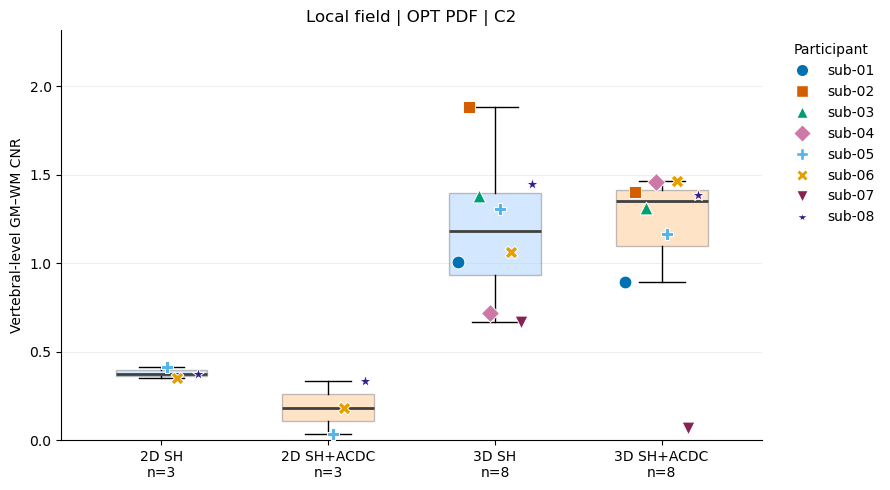

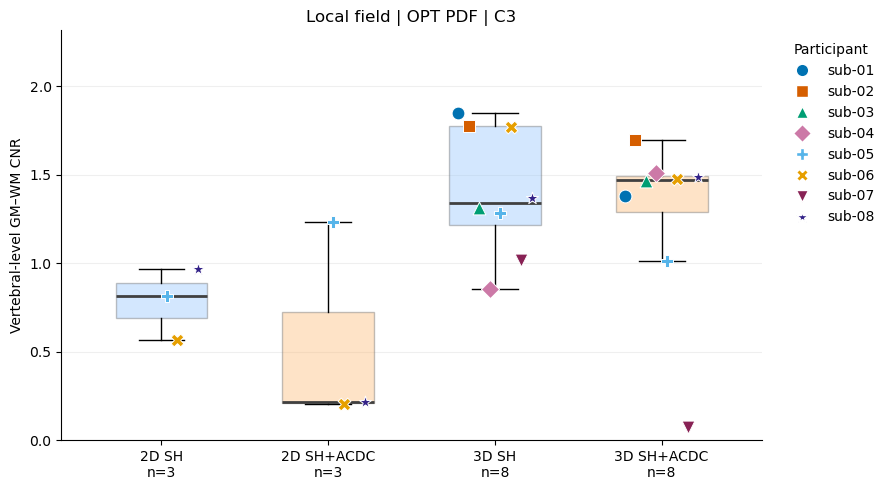

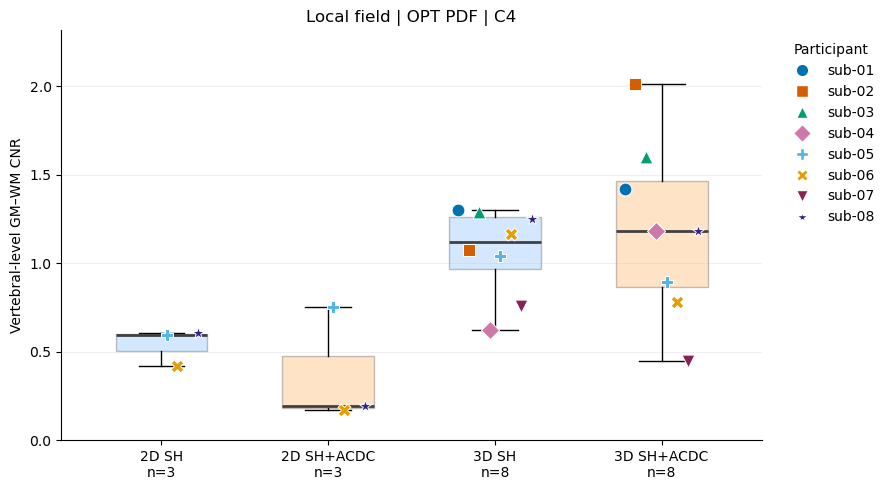

In [32]:
localfield_level_cnr_figures = {}

selected = vertebral_cnr_df.loc[
    vertebral_cnr_df["Outcome"] == "Local field"
]

values = selected.loc[
    np.isfinite(selected["CNR"]), "CNR"
]

localfield_ylim = (
    0,
    max(1.0, values.max() * 1.15) if len(values) else 1.0,
)

for level in LEVEL_CNR_LEVELS:
    level_label = f"C{level}" if level <= 7 else f"T{level - 7}"

    frame = selected.loc[
        selected["VertLevel"] == level
    ]

    fig, ax = plot_participant_boxes(
        frame,
        value_col="CNR",
        title=f"Local field | OPT PDF | {level_label}",
        ylabel="Vertebral-level GM–WM CNR",
        figsize=LEVEL_CNR_FIGSIZE,
        ylim=localfield_ylim,
    )

    localfield_level_cnr_figures[level] = (fig, ax)

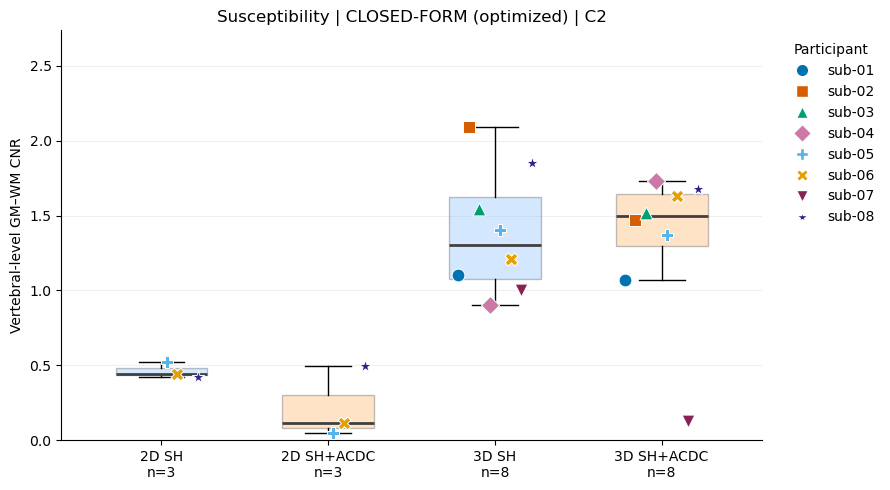

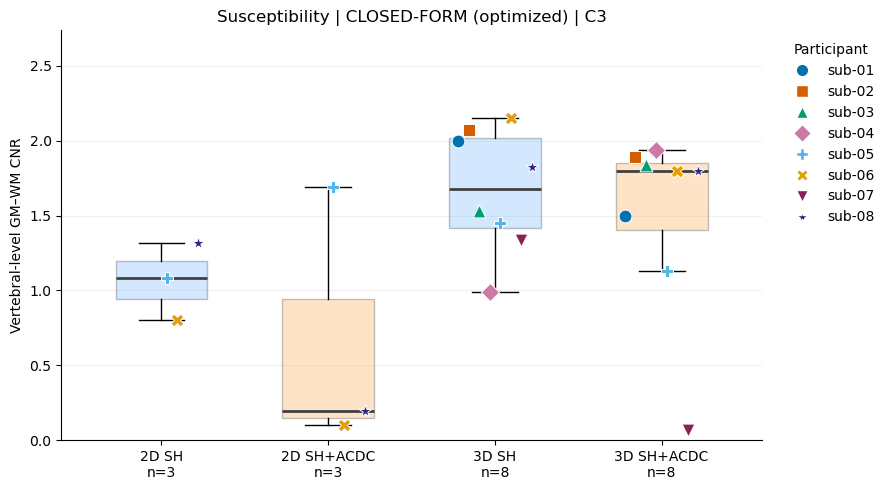

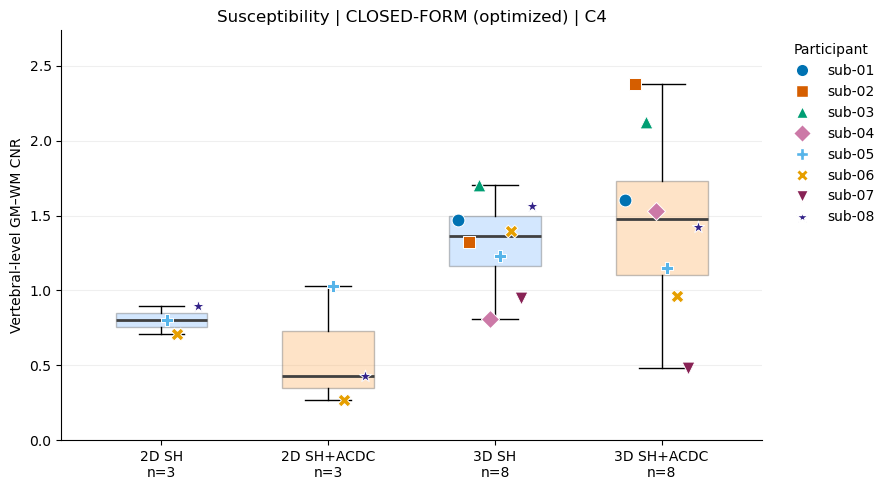

In [28]:
susceptibility_level_cnr_figures = {}

selected = vertebral_cnr_df.loc[
    vertebral_cnr_df["Outcome"] == "Susceptibility"
]

values = selected.loc[
    np.isfinite(selected["CNR"]), "CNR"
]

susceptibility_ylim = (
    0,
    max(1.0, values.max() * 1.15) if len(values) else 1.0,
)

for level in LEVEL_CNR_LEVELS:
    level_label = f"C{level}" if level <= 7 else f"T{level - 7}"

    frame = selected.loc[
        selected["VertLevel"] == level
    ]

    fig, ax = plot_participant_boxes(
        frame,
        value_col="CNR",
        title=(
            f"Susceptibility | {DI_LABELS[DI_METHOD]} "
            f"(optimized) | {level_label}"
        ),
        ylabel="Vertebral-level GM–WM CNR",
        figsize=LEVEL_CNR_FIGSIZE,
        ylim=susceptibility_ylim,
    )

    susceptibility_level_cnr_figures[level] = (fig, ax)

In [36]:
# ============================================================
# Vertebral-level CNR: paired SH vs SH+ACDC t-tests
# ============================================================

ALPHA = 0.05
test_rows = []

for outcome in ("Local field", "Susceptibility"):
    for dimension in ("2D", "3D"):
        for level in LEVEL_CNR_LEVELS:

            subset = vertebral_cnr_df.loc[
                (vertebral_cnr_df["Outcome"] == outcome)
                & (vertebral_cnr_df["Dimension"] == dimension)
                & (vertebral_cnr_df["VertLevel"] == level)
                & vertebral_cnr_df["Participant"].isin(
                    INCLUDED_PARTICIPANTS[dimension]
                )
            ]

            # Match the same participants between conditions.
            paired = paired_conditions(subset, "CNR")

            summary = paired_test_summary(
                paired["sh"],
                paired["sh_acdc"],
            )

            test_rows.append({
                "Outcome": outcome,
                "Dimension": dimension,
                "VertLevel": level,
                **summary,
            })

vertebral_cnr_ttests_df = (
    pd.DataFrame(test_rows)
    .rename(columns={
        "Before average": "SH mean CNR",
        "After average": "SH+ACDC mean CNR",
        "Difference (after-before)": "Difference (ACDC-SH)",
    })
)

# Holm adjustment across all tests in this cell.
# Retain raw p-values alongside adjusted values.
vertebral_cnr_ttests_df["p Holm"] = np.nan

valid = vertebral_cnr_ttests_df[
    "p raw (two-sided)"
].notna()

if valid.any():
    raw = vertebral_cnr_ttests_df.loc[
        valid, "p raw (two-sided)"
    ].to_numpy()

    order = np.argsort(raw)

    adjusted_sorted = np.minimum(
        1.0,
        np.maximum.accumulate(
            (len(raw) - np.arange(len(raw))) * raw[order]
        ),
    )

    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = adjusted_sorted

    vertebral_cnr_ttests_df.loc[valid, "p Holm"] = adjusted

# Leave results unavailable when there were insufficient paired data.
significance_column = f"Significant after Holm (alpha={ALPHA})"

vertebral_cnr_ttests_df[significance_column] = pd.Series(
    pd.NA,
    index=vertebral_cnr_ttests_df.index,
    dtype="boolean",
)

vertebral_cnr_ttests_df.loc[valid, significance_column] = (
    vertebral_cnr_ttests_df.loc[valid, "p Holm"] < ALPHA
)

display(vertebral_cnr_ttests_df.round(6))

,Outcome,Dimension,VertLevel,N paired,SH mean CNR,SH+ACDC mean CNR,Difference (ACDC-SH),Difference CI95 low,Difference CI95 high,t statistic,p raw (two-sided),p Holm,Significant after Holm (alpha=0.05)
0,Local field,2D,2,3,0.379471,0.184043,-0.195429,-0.621736,0.230878,-1.972433,0.187307,1.0,False
1,Local field,2D,3,3,0.781416,0.550179,-0.231237,-1.715933,1.253460,-0.670124,0.571792,1.0,False
2,Local field,2D,4,3,0.538022,0.370910,-0.167112,-0.895380,0.561156,-0.987310,0.427565,1.0,False
3,Local field,3D,2,8,1.183239,1.142890,-0.040349,-0.403285,0.322587,-0.262887,0.800207,1.0,False
4,Local field,3D,3,8,1.403565,1.260497,-0.143068,-0.540089,0.253953,-0.852102,0.422350,1.0,False
5,Local field,3D,4,8,1.061617,1.188725,0.127108,-0.252942,0.507158,0.790849,0.454987,1.0,False
6,Susceptibility,2D,2,3,0.461915,0.218126,-0.243788,-0.952268,0.464691,-1.480548,0.276880,1.0,False
7,Susceptibility,2D,3,3,1.068029,0.662487,-0.405542,-2.640494,1.829411,-0.780734,0.516696,1.0,False
8,Susceptibility,2D,4,3,0.803681,0.574199,-0.229482,-1.210625,0.751662,-1.006357,0.420211,1.0,False
9,Susceptibility,3D,2,8,1.389040,1.325798,-0.063241,-0.512648,0.386166,-0.332754,0.749064,1.0,False


## Final GM and WM box plot for Chi values

In [37]:
susceptibility_values_df = cnr_df.loc[
    cnr_df["Outcome"] == "Susceptibility"
].copy()

method_label = DI_LABELS[DI_METHOD]


def susceptibility_plot_limits(frame, value_col):
    values = frame.loc[
        np.isfinite(frame[value_col]), value_col
    ]

    if values.empty:
        raise ValueError(f"No finite values available for {value_col}")

    low = values.min()
    high = values.max()

    padding = max(
        0.12 * (high - low),
        0.05 * max(abs(low), abs(high)),
        1e-6,
    )

    return low - padding, high + padding

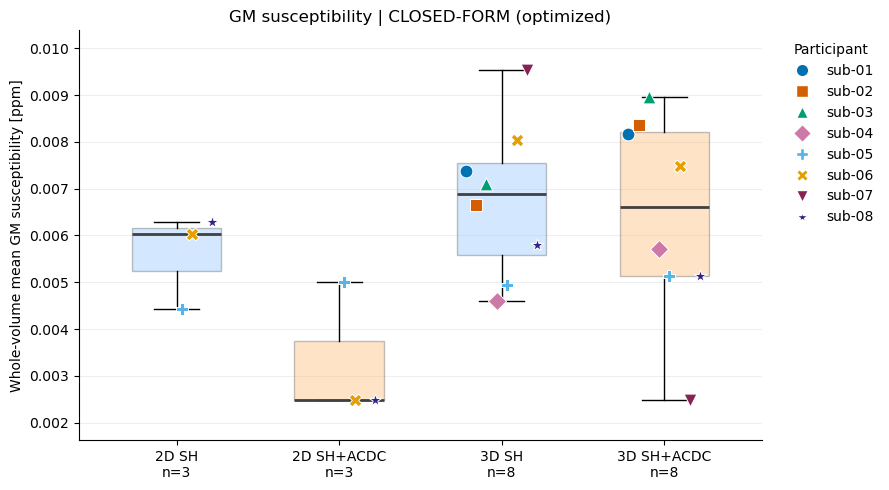

In [38]:
fig_gm_chi, ax_gm_chi = plot_participant_boxes(
    susceptibility_values_df,
    value_col="GM Mean",
    title=f"GM susceptibility | {method_label} (optimized)",
    ylabel="Whole-volume mean GM susceptibility [ppm]",
    figsize=(9, 5),
    ylim=susceptibility_plot_limits(
        susceptibility_values_df,
        "GM Mean",
    ),
)

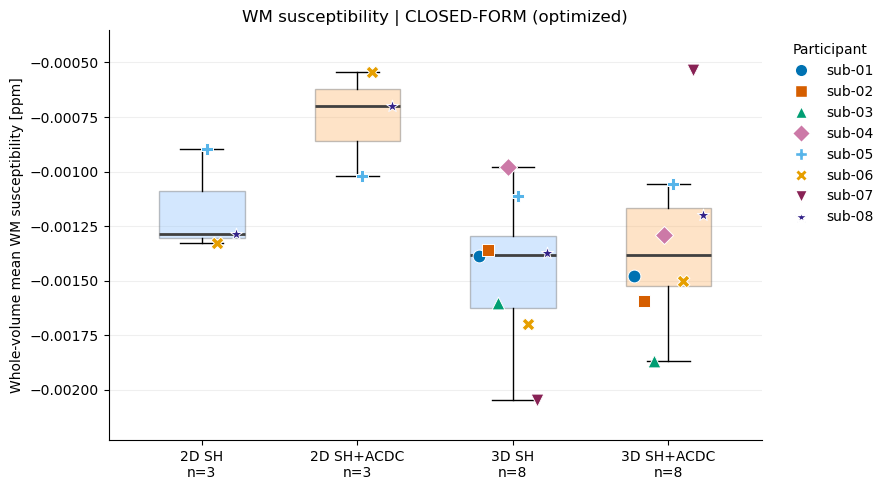

In [39]:
fig_wm_chi, ax_wm_chi = plot_participant_boxes(
    susceptibility_values_df,
    value_col="WM Mean",
    title=f"WM susceptibility | {method_label} (optimized)",
    ylabel="Whole-volume mean WM susceptibility [ppm]",
    figsize=(9, 5),
    ylim=susceptibility_plot_limits(
        susceptibility_values_df,
        "WM Mean",
    ),
)

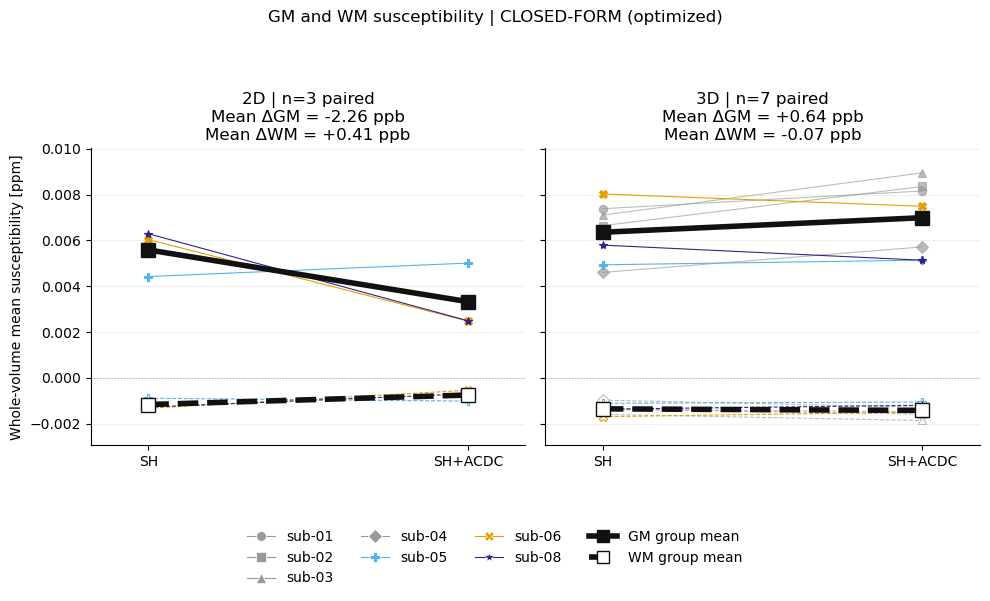

In [36]:
# ============================================================
# GM and WM susceptibility together: paired SH vs SH+ACDC
# ============================================================

SHOW_CHI_MEAN = True

chi_source = cnr_df.loc[
    cnr_df["Outcome"] == "Susceptibility"
].copy()

paired_chi = {}

required_columns = pd.MultiIndex.from_product([
    ["GM Mean", "WM Mean"],
    ["sh", "sh_acdc"],
])

for dimension in ("2D", "3D"):
    selected = chi_source.loc[
        (chi_source["Dimension"] == dimension)
        & chi_source["Participant"].isin(
            INCLUDED_PARTICIPANTS[dimension]
        )
    ]

    # Same participants for both tissues and both shim conditions.
    paired_chi[dimension] = (
        selected
        .pivot(
            index="Participant",
            columns="Condition",
            values=["GM Mean", "WM Mean"],
        )
        .reindex(columns=required_columns)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

highlighted_chi = set(paired_chi["2D"].index)

tissue_styles = {
    "GM": {
        "column": "GM Mean",
        "linestyle": "-",
    },
    "WM": {
        "column": "WM Mean",
        "linestyle": "--",
    },
}

fig_chi_combined, axes_chi_combined = plt.subplots(
    1, 2,
    figsize=(10, 6),
    sharey=True,
)

for ax, dimension in zip(
    axes_chi_combined,
    ("2D", "3D"),
):
    paired = paired_chi[dimension]

    # Gray subjects first; highlighted subjects on top.
    plot_order = sorted(
        paired.index,
        key=lambda p: (p in highlighted_chi, p),
    )

    for participant_id in plot_order:
        style = PARTICIPANT_STYLES[participant_id]
        highlighted = participant_id in highlighted_chi

        color = (
            style["color"]
            if highlighted else OTHER_PARTICIPANT_COLOR
        )

        for tissue, tissue_style in tissue_styles.items():
            column = tissue_style["column"]

            ax.plot(
                [0, 1],
                [
                    paired.loc[participant_id, (column, "sh")],
                    paired.loc[participant_id, (column, "sh_acdc")],
                ],
                color=color,
                linestyle=tissue_style["linestyle"],
                marker=style["marker"],
                linewidth=SUBJECT_LINEWIDTH,
                markersize=SUBJECT_MARKERSIZE,
                markerfacecolor=color if tissue == "GM" else "white",
                markeredgecolor=color,
                markeredgewidth=0.8,
                alpha=1.0 if highlighted else 0.65,
                zorder=3 if highlighted else 2,
            )

    # Bold tissue-specific group means.
    if SHOW_CHI_MEAN and len(paired):
        for tissue, tissue_style in tissue_styles.items():
            column = tissue_style["column"]

            ax.plot(
                [0, 1],
                [
                    paired[(column, "sh")].mean(),
                    paired[(column, "sh_acdc")].mean(),
                ],
                color="#111111",
                linestyle=tissue_style["linestyle"],
                marker="s",
                linewidth=MEAN_LINEWIDTH,
                markersize=MEAN_MARKERSIZE,
                markerfacecolor=(
                    "#111111" if tissue == "GM" else "white"
                ),
                markeredgecolor="#111111",
                markeredgewidth=1,
                zorder=6,
            )

    ax.axhline(
        0,
        color="0.65",
        linestyle=":",
        linewidth=0.8,
        zorder=1,
    )

    if len(paired):
        delta_gm_ppb = 1000 * (
            paired[("GM Mean", "sh_acdc")]
            - paired[("GM Mean", "sh")]
        ).mean()

        delta_wm_ppb = 1000 * (
            paired[("WM Mean", "sh_acdc")]
            - paired[("WM Mean", "sh")]
        ).mean()

        ax.set_title(
            f"{dimension} | n={len(paired)} paired\n"
            f"Mean ΔGM = {delta_gm_ppb:+.2f} ppb\n"
            f"Mean ΔWM = {delta_wm_ppb:+.2f} ppb"
        )
    else:
        ax.set_title(f"{dimension} | No complete pairs")
    ax.set_xticks([0, 1], ["SH", "SH+ACDC"])
    ax.set_xlim(-0.18, 1.18)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if paired.empty:
        ax.text(
            0.5, 0.5,
            "No complete pairs",
            ha="center",
            transform=ax.transAxes,
        )

# Signed limits: include both tissues and preserve negative values.
all_values = np.concatenate([
    frame.to_numpy().ravel()
    for frame in paired_chi.values()
])
all_values = all_values[np.isfinite(all_values)]

if len(all_values):
    low = min(0.0, all_values.min())
    high = max(0.0, all_values.max())
    padding = max(0.10 * (high - low), 1e-6)
    axes_chi_combined[0].set_ylim(
        low - padding,
        high + padding,
    )

axes_chi_combined[0].set_ylabel(
    "Whole-volume mean susceptibility [ppm]"
)

# Individual participant legend, including each gray participant.
all_chi_participants = (
    set(paired_chi["2D"].index)
    | set(paired_chi["3D"].index)
)

handles = trajectory_legend_handles(
    participant_ids=all_chi_participants,
    highlighted_ids=highlighted_chi,
    show_mean=False,
)

# Explain tissue styles and the bold mean lines.
for tissue, tissue_style in tissue_styles.items():
    handles.append(
        Line2D(
            [], [],
            color="#111111",
            linestyle=tissue_style["linestyle"],
            marker="s",
            linewidth=(
                MEAN_LINEWIDTH
                if SHOW_CHI_MEAN else SUBJECT_LINEWIDTH
            ),
            markersize=8,
            markerfacecolor=(
                "#111111" if tissue == "GM" else "white"
            ),
            markeredgecolor="#111111",
            label=(
                f"{tissue} group mean"
                if SHOW_CHI_MEAN else tissue
            ),
        )
    )

fig_chi_combined.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
)

fig_chi_combined.suptitle(
    f"GM and WM susceptibility | "
    f"{DI_LABELS[DI_METHOD]} (optimized)",
    y=0.99,
)

fig_chi_combined.tight_layout(rect=[0, 0.20, 1, 0.93])
plt.show()

# Optional:
# fig_chi_combined.savefig(
#     "GM_WM_susceptibility_combined.png",
#     dpi=300,
#     bbox_inches="tight",
# )

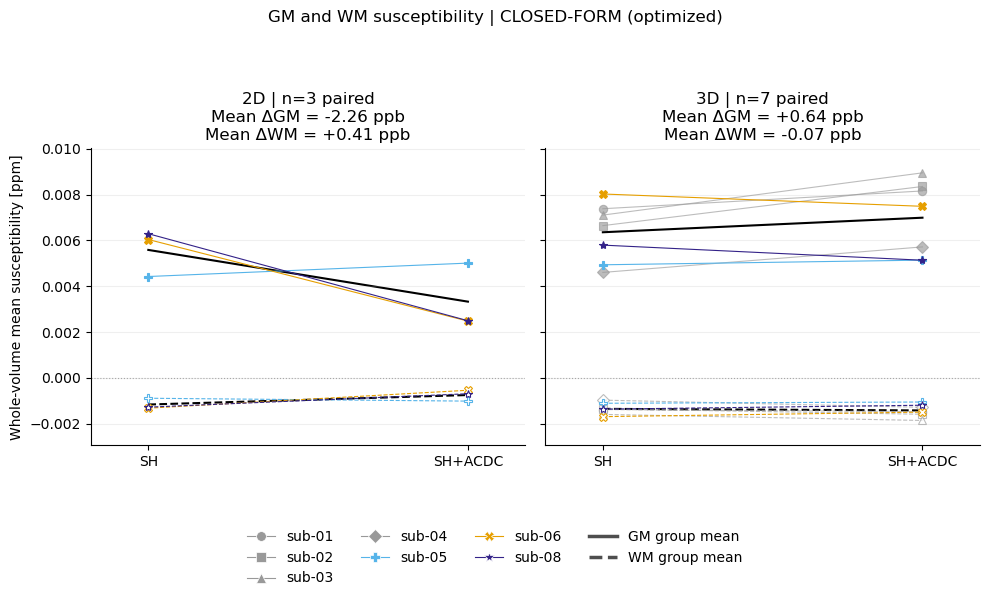

In [51]:
# ============================================================
# GM and WM susceptibility together: paired SH vs SH+ACDC
# ============================================================

SHOW_CHI_MEAN = True

chi_source = cnr_df.loc[
    cnr_df["Outcome"] == "Susceptibility"
].copy()

paired_chi = {}

required_columns = pd.MultiIndex.from_product([
    ["GM Mean", "WM Mean"],
    ["sh", "sh_acdc"],
])

for dimension in ("2D", "3D"):
    selected = chi_source.loc[
        (chi_source["Dimension"] == dimension)
        & chi_source["Participant"].isin(
            INCLUDED_PARTICIPANTS[dimension]
        )
    ]

    # Same participants for both tissues and both shim conditions.
    paired_chi[dimension] = (
        selected
        .pivot(
            index="Participant",
            columns="Condition",
            values=["GM Mean", "WM Mean"],
        )
        .reindex(columns=required_columns)
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

highlighted_chi = set(paired_chi["2D"].index)

tissue_styles = {
    "GM": {
        "column": "GM Mean",
        "linestyle": "-",
    },
    "WM": {
        "column": "WM Mean",
        "linestyle": "--",
    },
}

fig_chi_combined, axes_chi_combined = plt.subplots(
    1, 2,
    figsize=(10, 6),
    sharey=True,
)

for ax, dimension in zip(
    axes_chi_combined,
    ("2D", "3D"),
):
    paired = paired_chi[dimension]

    # Gray subjects first; highlighted subjects on top.
    plot_order = sorted(
        paired.index,
        key=lambda p: (p in highlighted_chi, p),
    )

    for participant_id in plot_order:
        style = PARTICIPANT_STYLES[participant_id]
        highlighted = participant_id in highlighted_chi

        color = (
            style["color"]
            if highlighted else OTHER_PARTICIPANT_COLOR
        )

        for tissue, tissue_style in tissue_styles.items():
            column = tissue_style["column"]

            ax.plot(
                [0, 1],
                [
                    paired.loc[participant_id, (column, "sh")],
                    paired.loc[participant_id, (column, "sh_acdc")],
                ],
                color=color,
                linestyle=tissue_style["linestyle"],
                marker=style["marker"],
                linewidth=SUBJECT_LINEWIDTH,
                markersize=SUBJECT_MARKERSIZE,
                markerfacecolor=color if tissue == "GM" else "white",
                markeredgecolor=color,
                markeredgewidth=0.8,
                alpha=1.0 if highlighted else 0.65,
                zorder=3 if highlighted else 2,
            )

    # Bold tissue-specific group means.
    # Mean lines remain visible, behind the participant data.
    if SHOW_CHI_MEAN and len(paired):
        for tissue, tissue_style in tissue_styles.items():
            column = tissue_style["column"]

            ax.plot(
                [0, 1],
                [
                    paired[(column, "sh")].mean(),
                    paired[(column, "sh_acdc")].mean(),
                ],
                color="#000000",
                linestyle=tissue_style["linestyle"],
                linewidth=1.5,
                alpha=1,
                marker=None,
                zorder=1.5,
            )


    ax.axhline(
        0,
        color="0.65",
        linestyle=":",
        linewidth=0.8,
        zorder=1,
    )

    if len(paired):
        delta_gm_ppb = 1000 * (
            paired[("GM Mean", "sh_acdc")]
            - paired[("GM Mean", "sh")]
        ).mean()

        delta_wm_ppb = 1000 * (
            paired[("WM Mean", "sh_acdc")]
            - paired[("WM Mean", "sh")]
        ).mean()

        ax.set_title(
            f"{dimension} | n={len(paired)} paired\n"
            f"Mean ΔGM = {delta_gm_ppb:+.2f} ppb\n"
            f"Mean ΔWM = {delta_wm_ppb:+.2f} ppb"
        )
    else:
        ax.set_title(f"{dimension} | No complete pairs")
    ax.set_xticks([0, 1], ["SH", "SH+ACDC"])
    ax.set_xlim(-0.18, 1.18)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if paired.empty:
        ax.text(
            0.5, 0.5,
            "No complete pairs",
            ha="center",
            transform=ax.transAxes,
        )

# Signed limits: include both tissues and preserve negative values.
all_values = np.concatenate([
    frame.to_numpy().ravel()
    for frame in paired_chi.values()
])
all_values = all_values[np.isfinite(all_values)]

if len(all_values):
    low = min(0.0, all_values.min())
    high = max(0.0, all_values.max())
    padding = max(0.10 * (high - low), 1e-6)
    axes_chi_combined[0].set_ylim(
        low - padding,
        high + padding,
    )

axes_chi_combined[0].set_ylabel(
    "Whole-volume mean susceptibility [ppm]"
)

# Individual participant legend, including each gray participant.
all_chi_participants = (
    set(paired_chi["2D"].index)
    | set(paired_chi["3D"].index)
)

handles = trajectory_legend_handles(
    participant_ids=all_chi_participants,
    highlighted_ids=highlighted_chi,
    show_mean=False,
)

# Explain tissue styles and the bold mean lines.
for tissue, tissue_style in tissue_styles.items():
    handles.append(
        Line2D(
            [], [],
            color="#222222",
            linestyle=tissue_style["linestyle"],
            linewidth=2.5,
            alpha=0.8,
            label=f"{tissue} group mean" if SHOW_CHI_MEAN else tissue,
        )
    )

    

fig_chi_combined.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
)

fig_chi_combined.suptitle(
    f"GM and WM susceptibility | "
    f"{DI_LABELS[DI_METHOD]} (optimized)",
    y=0.99,
)

fig_chi_combined.tight_layout(rect=[0, 0.20, 1, 0.93])
plt.show()

# Optional:
# fig_chi_combined.savefig(
#     "GM_WM_susceptibility_combined.png",
#     dpi=300,
#     bbox_inches="tight",
# )

In [37]:
from IPython.display import display, Markdown

CAPTION_UNITS = "ppm"  # "ppm" or "ppb"
scale = {"ppm": 1, "ppb": 1000}[CAPTION_UNITS]
decimals = 4 if CAPTION_UNITS == "ppm" else 1

caption_rows = []
caption_sections = []

for dimension in ("3D", "2D"):
    paired = paired_chi[dimension]
    n = len(paired)

    if n == 0:
        continue

    condition_text = []

    for condition, label in (
        ("sh", "SH"),
        ("sh_acdc", "SH+ACDC"),
    ):
        wm_values = paired[("WM Mean", condition)] * scale
        gm_values = paired[("GM Mean", condition)] * scale

        wm_mean = wm_values.mean()
        gm_mean = gm_values.mean()

        wm_sd = wm_values.std(ddof=1)
        gm_sd = gm_values.std(ddof=1)

        caption_rows.append({
            "Dimension": dimension,
            "Condition": label,
            "N paired": n,
            "Units": CAPTION_UNITS,
            "WM mean": wm_mean,
            "WM between-participant SD": wm_sd,
            "GM mean": gm_mean,
            "GM between-participant SD": gm_sd,
        })

        if n >= 2:
            values_text = (
                f"{wm_mean:.{decimals}f} ± {wm_sd:.{decimals}f} "
                f"and {gm_mean:.{decimals}f} ± {gm_sd:.{decimals}f}"
            )
        else:
            values_text = (
                f"{wm_mean:.{decimals}f} and {gm_mean:.{decimals}f} "
                "(between-participant SD unavailable)"
            )

        condition_text.append(f"{label}, {values_text}")

    caption_sections.append(
        f"**{dimension} (n = {n}):** "
        + "; ".join(condition_text)
        + "."
    )

chi_caption_summary_df = pd.DataFrame(caption_rows)

chi_updated_caption = (
    "**Whole-volume WM and GM susceptibility under SH and SH+ACDC.** "
    f"Group means ± between-participant SD "
    f"({CAPTION_UNITS}; WM and GM, respectively) were: "
    + " ".join(caption_sections)
)

display(chi_caption_summary_df.round(decimals))
display(Markdown(chi_updated_caption))

,Dimension,Condition,N paired,Units,WM mean,WM between-participant SD,GM mean,GM between-participant SD
0,3D,SH,7,ppm,-0.0014,0.0003,0.0064,0.0013
1,3D,SH+ACDC,7,ppm,-0.0014,0.0003,0.0070,0.0016
2,2D,SH,3,ppm,-0.0012,0.0002,0.0056,0.0010
3,2D,SH+ACDC,3,ppm,-0.0008,0.0002,0.0033,0.0015


**Whole-volume WM and GM susceptibility under SH and SH+ACDC.** Group means ± between-participant SD (ppm; WM and GM, respectively) were: **3D (n = 7):** SH, -0.0014 ± 0.0003 and 0.0064 ± 0.0013; SH+ACDC, -0.0014 ± 0.0003 and 0.0070 ± 0.0016. **2D (n = 3):** SH, -0.0012 ± 0.0002 and 0.0056 ± 0.0010; SH+ACDC, -0.0008 ± 0.0002 and 0.0033 ± 0.0015.

In [39]:
from IPython.display import display, Markdown

ALPHA = 0.05

chi_test_rows = []
chi_result_sentences = []


def chi_p_text(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


for dimension in ("3D", "2D"):
    paired = paired_chi[dimension]
    tissue_results = []

    for tissue in ("GM", "WM"):
        column = f"{tissue} Mean"

        summary = paired_test_summary(
            paired[(column, "sh")],
            paired[(column, "sh_acdc")],
        )

        n = summary["N paired"]
        t_stat = summary["t statistic"]
        p = summary["p raw (two-sided)"]

        chi_test_rows.append({
            "Dimension": dimension,
            "Tissue": tissue,
            "Units": "ppm",
            **summary,
        })

        if n < 2 or not np.isfinite(p):
            tissue_results.append(
                f"the {tissue} comparison had insufficient data "
                "for a valid paired t-test"
            )
            continue

        significance = (
            "differed significantly"
            if p < ALPHA
            else "did not differ significantly"
        )

        tissue_results.append(
            f"{tissue} mean susceptibility {significance} "
            f"between SH and SH+ACDC "
            f"(t({n - 1}) = {t_stat:.2f}, {chi_p_text(p)})"
        )

    chi_result_sentences.append(
        f"For {dimension} acquisitions, "
        + "; ".join(tissue_results)
        + "."
    )

chi_mean_ttests_df = pd.DataFrame(chi_test_rows)

chi_results_text = (
    "Figure X compares whole-volume GM and WM susceptibility "
    "across shimming conditions and participants. "
    + " ".join(chi_result_sentences)
)

display(chi_mean_ttests_df.round(6))
display(Markdown(chi_results_text))

print(
    "Exploratory paired, two-sided t-tests; "
    "p-values are unadjusted for the four comparisons. "
    "Differences and t-statistics use SH+ACDC minus SH."
)

,Dimension,Tissue,Units,N paired,Before average,After average,Difference (after-before),Difference CI95 low,Difference CI95 high,t statistic,p raw (two-sided)
0,3D,GM,ppm,7,0.006359,0.006995,0.000636,-0.000298,0.001570,1.666676,0.146628
1,3D,WM,ppm,7,-0.001358,-0.001427,-0.000069,-0.000265,0.000128,-0.851611,0.427107
2,2D,GM,ppm,3,0.005587,0.003327,-0.002260,-0.008392,0.003871,-1.586232,0.253580
3,2D,WM,ppm,3,-0.001169,-0.000754,0.000414,-0.000773,0.001602,1.501504,0.272050


Figure X compares whole-volume GM and WM susceptibility across shimming conditions and participants. For 3D acquisitions, GM mean susceptibility did not differ significantly between SH and SH+ACDC (t(6) = 1.67, p = 0.147); WM mean susceptibility did not differ significantly between SH and SH+ACDC (t(6) = -0.85, p = 0.427). For 2D acquisitions, GM mean susceptibility did not differ significantly between SH and SH+ACDC (t(2) = -1.59, p = 0.254); WM mean susceptibility did not differ significantly between SH and SH+ACDC (t(2) = 1.50, p = 0.272).

Exploratory paired, two-sided t-tests; p-values are unadjusted for the four comparisons. Differences and t-statistics use SH+ACDC minus SH.


## PAM 50

In [40]:
chi_035_2D_bl_chimap_reg_path = r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_035\qsm_processing\2D\baseline\sc-qsm-output\chi-035_2D_bl\pam50_reg\opt_closedForm_to_PAM50\III_source_to_PAM50\chi-035_2D_bl_desc-chimap_to_PAM50_cropped.nii.gz"
chi_035_2D_bl_chimap_reg_img = nib.load(chi_035_2D_bl_chimap_reg_path)

In [41]:
chi_035_2D_bl_chimap_reg_data = chi_035_2D_bl_chimap_reg_img.get_fdata()
chi_035_2D_sh_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_035\qsm_processing\2D\shim\sc-qsm-output\chi-035_2D_sh\pam50_reg\opt_closedForm_to_PAM50\III_source_to_PAM50\chi-035_2D_sh_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_036_2D_bl_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_036\qsm_processing\2D\baseline\sc-qsm-output\chi-036_2D_bl\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-036_2D_bl_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_036_2D_sh_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_036\qsm_processing\2D\shim\sc-qsm-output\chi-036_2D_sh\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-036_2D_sh_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_038_2D_bl_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_038\qsm_processing\2D\baseline\sc-qsm-output\chi-038_2D_bl\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-038_2D_bl_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_038_2D_sh_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_038\qsm_processing\2D\shim\sc-qsm-output\chi-038_2D_sh\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-038_2D_sh_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()

In [42]:
mean_2D_bl_chimap = np.mean([
    chi_035_2D_bl_chimap_reg_data,
    chi_036_2D_bl_chimap_reg_data,
    chi_038_2D_bl_chimap_reg_data,
], axis=0)

mean_2D_sh_chimap = np.mean([
    chi_035_2D_sh_chimap_reg_data,
    chi_036_2D_sh_chimap_reg_data,
    chi_038_2D_sh_chimap_reg_data,
], axis=0)

In [44]:
reference = chi_035_2D_bl_chimap_reg_img


mean_2D_bl_outimg = nib.Nifti1Image(
        mean_2D_bl_chimap.astype(np.float32),
        reference.affine,
        header=reference.header.copy(),
    )
mean_2D_bl_outimg.set_data_dtype(np.float32)
nib.save(mean_2D_bl_outimg, r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\registered_2_PAM50\mc_acdc\2D/mean_2D_bl_chimap_to_PAM50.nii.gz")

mean_2D_sh_outimg = nib.Nifti1Image(
        mean_2D_sh_chimap.astype(np.float32),
        reference.affine,
        header=reference.header.copy(),
    )
mean_2D_sh_outimg.set_data_dtype(np.float32)
nib.save(mean_2D_sh_outimg, r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\registered_2_PAM50\mc_acdc\2D/mean_2D_sh_chimap_to_PAM50.nii.gz")

In [45]:
chi_035_3D_bl_chimap_reg_path = r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_035\qsm_processing\3D\baseline\sc-qsm-output\chi-035_3D_bl\pam50_reg\opt_closedForm_to_PAM50\III_source_to_PAM50\chi-035_3D_bl_desc-chimap_to_PAM50_cropped.nii.gz"
chi_035_3D_bl_chimap_reg_img = nib.load(chi_035_3D_bl_chimap_reg_path)

In [46]:
chi_035_3D_bl_chimap_reg_data = chi_035_3D_bl_chimap_reg_img.get_fdata()
chi_035_3D_sh_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_035\qsm_processing\3D\shim\sc-qsm-output\chi-035_3D_sh\pam50_reg\opt_closedForm_to_PAM50\III_source_to_PAM50\chi-035_3D_sh_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_036_3D_bl_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_036\qsm_processing\3D\baseline\sc-qsm-output\chi-036_3D_bl\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-036_3D_bl_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_036_3D_sh_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_036\qsm_processing\3D\shim\sc-qsm-output\chi-036_3D_sh\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-036_3D_sh_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_038_3D_bl_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_038\qsm_processing\3D\baseline\sc-qsm-output\chi-038_3D_bl\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-038_3D_bl_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()
chi_038_3D_sh_chimap_reg_data = nib.load(r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\chi_038\qsm_processing\3D\shim\sc-qsm-output\chi-038_3D_sh\pam50_reg\opt_closedForm__opt_pdf_to_PAM50\III_source_to_PAM50\chi-038_3D_sh_desc-chimap_to_PAM50_cropped.nii.gz").get_fdata()


In [47]:
mean_3D_bl_chimap = np.mean([
    chi_035_3D_bl_chimap_reg_data,
    chi_036_3D_bl_chimap_reg_data,
    chi_038_3D_bl_chimap_reg_data,
], axis=0)

mean_3D_sh_chimap = np.mean([
    chi_035_3D_sh_chimap_reg_data,
    chi_036_3D_sh_chimap_reg_data,
    chi_038_3D_sh_chimap_reg_data,
], axis=0)

In [48]:
reference = chi_035_3D_bl_chimap_reg_img


mean_3D_bl_outimg = nib.Nifti1Image(
        mean_3D_bl_chimap.astype(np.float32),
        reference.affine,
        header=reference.header.copy(),
    )
mean_3D_bl_outimg.set_data_dtype(np.float32)
nib.save(mean_3D_bl_outimg, r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\registered_2_PAM50\mc_acdc\3D/mean_3D_bl_chimap_to_PAM50.nii.gz")

mean_3D_sh_outimg = nib.Nifti1Image(
        mean_3D_sh_chimap.astype(np.float32),
        reference.affine,
        header=reference.header.copy(),
    )
mean_3D_sh_outimg.set_data_dtype(np.float32)
nib.save(mean_3D_sh_outimg, r"R:\soothsayer\sc_qsm\sc_qsm\neuropoly_data\registered_2_PAM50\mc_acdc\3D/mean_3D_sh_chimap_to_PAM50.nii.gz")